<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/VB-day5/VB_Day5_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision 기본 모델 Day 5 — 세그멘테이션 · 포즈 · ONNX · 성능 측정 → 위험구역 침입 감지

**온디바이스 AI · Vision 기본 모델 5/5 (마지막 날) · 11/3(화)** · Google Colab (GPU 런타임, 성능 측정은 CPU) · PyTorch · ultralytics · ONNX Runtime

어제는 '무엇이 어디에' (박스) 까지 왔습니다. 오늘은 박스로는 부족한 문제 — **어떤 모양으로** (세그멘테이션), **어떤 자세로** (포즈) — 를 다루고, 모델을 **ONNX** 로 내보내 **CPU 성능을 수치로** 남깁니다. 마지막으로 5일 동안 만든 것을 모아 **위험구역 침입 감지기**를 완성합니다.

오늘의 목표

1. 박스의 한계를 데이터로 확인하고, 분류 · 탐지 · 세그멘테이션 · 포즈의 출력 차이를 정리한다.
2. Encoder-Decoder · Transposed Conv 를 이해하고, 마스크 **mIoU** 를 직접 구현해 YOLOv8n-seg 를 평가한다.
3. COCO 17 관절을 읽고 관절 각도로 **쓰러짐 판정 규칙**을 만든다.
4. 모델을 **ONNX** 로 내보내고 ONNX Runtime 결과가 PyTorch 와 같은지 검증한다.
5. warm-up · 평균 · p95 · FPS · 스레드 수로 **CPU baseline 성능표**를 만든다 — 내일부터 ONNX·TensorRT 과목의 비교 기준.
6. ONNX 탐지기 + ROI 다각형 + 경보 로직으로 **위험구역 침입 감지** (결과 영상 + CSV 로그) 를 만든다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 4 복습 퀴즈 · 박스로는 부족한 상황 |
| 2 | 10:00–10:50 | 세그멘테이션 — Encoder-Decoder · mIoU |
| 3 | 11:00–11:50 | 포즈 추정 — 관절 · 쓰러짐 규칙 |
| 4 | 13:00–13:50 | 비전 태스크 정리 — 출력 텐서 · 시나리오 매칭 |
| 5 | 14:00–14:50 | ONNX export · ONNX Runtime |
| 6 | 15:00–15:50 | 성능 측정법 — baseline 성능표 |
| 7 | 16:00–16:50 | 종합 미니 프로젝트 — 위험구역 침입 감지 |
| 8 | 17:00–17:50 | 발표 · 최종 필기 퀴즈 30문항 · baseline 제출 |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → T4 GPU* 를 고르고, *파일 → Drive에 사본 저장* 후 사본에서 작업합니다.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다.
3. 막히면 **🔒 정답 보기** 셀을 실행하세요. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
4. 7교시 미니 프로젝트는 이 노트북 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/VB_Day5.pdf](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/VB_Day5.pdf) |

**오늘의 데이터 · 모델** — Penn-Fudan (이번에는 **마스크**도 씁니다), Day 4 의 보행자 영상 `people.mp4`, ultralytics **YOLOv8n · YOLOv8n-seg · YOLOv8n-pose** (같은 몸통에 head 만 다른 세 모델), torchvision MobileNetV3-Small (Day 3).

In [ ]:
# ▶ 설치 셀 — ultralytics · ONNX · ONNX Runtime. 처음 한 번, 약 1분
%pip install -q ultralytics onnx onnxruntime onnxslim

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, re, glob, time, json, copy, base64, inspect, subprocess, urllib.request, zipfile, csv
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from IPython.display import HTML, display

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (6, 4)
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RAW_D4 = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4"
PF = "PennFudanPed"

def load_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

def draw_boxes(img, boxes, color=(0, 255, 0), labels=None, thick=2):
    out = img.copy()
    for k, b in enumerate(np.asarray(boxes).reshape(-1, 4)):
        x1, y1, x2, y2 = [int(round(v)) for v in b]
        cv2.rectangle(out, (x1, y1), (x2, y2), color, thick)
        if labels is not None:
            cv2.putText(out, str(labels[k]), (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
    return out

def show(imgs, titles=None, cols=4, size=3.2):
    imgs = list(imgs); rows = (len(imgs) + cols - 1) // cols
    plt.figure(figsize=(size * min(cols, len(imgs)), size * rows))
    for i, im in enumerate(imgs):
        plt.subplot(rows, min(cols, len(imgs)), i + 1); plt.imshow(im); plt.axis("off")
        if titles is not None: plt.title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

# ── Day 4 에서 만든 함수 (iou_nms_map.py · 6교시) ──────────────────
def iou(box, boxes):
    box = np.asarray(box, float); boxes = np.asarray(boxes, float).reshape(-1, 4)
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda b: (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return inter / (area(box) + area(boxes) - inter)

def iou_matrix(A, B):
    A = np.asarray(A, float).reshape(-1, 4); B = np.asarray(B, float).reshape(-1, 4)
    x1 = np.maximum(A[:, None, 0], B[None, :, 0]); y1 = np.maximum(A[:, None, 1], B[None, :, 1])
    x2 = np.minimum(A[:, None, 2], B[None, :, 2]); y2 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aA = (A[:, 2] - A[:, 0]) * (A[:, 3] - A[:, 1]); aB = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
    return inter / (aA[:, None] + aB[None, :] - inter)

def nms(boxes, scores, iou_thr=0.5):
    boxes = np.asarray(boxes, float); scores = np.asarray(scores, float)
    order = np.argsort(-scores); keep = []
    while order.size > 0:
        i = order[0]; keep.append(i); rest = order[1:]
        order = rest[iou(boxes[i], boxes[rest]) <= iou_thr]
    return np.array(keep, dtype=int)

def letterbox(img, size=640, color=114):
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    nw, nh = round(w * r), round(h * r)
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (size - nh) // 2, (size - nw) // 2
    out = np.full((size, size, 3), color, dtype=np.uint8)
    out[top:top + nh, left:left + nw] = resized
    return out, r, (left, top)

def decode_yolo(out, conf_thr=0.25, iou_thr=0.7, cls=0):
    p = np.asarray(out)[0].T                              # (8400, 84)
    boxes_c, cls_scores = p[:, :4], p[:, 4:]
    best, conf = cls_scores.argmax(1), cls_scores.max(1)
    m = (conf > conf_thr) & (best == cls)
    cx, cy, w, h = boxes_c[m].T
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)
    keep = nms(boxes, conf[m], iou_thr)
    return boxes[keep], conf[m][keep]

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", device, "| CPU 코어", os.cpu_count())

In [ ]:
# ▶ 데이터 셀 — Penn-Fudan (약 50 MB) · 보행자 영상 (Day 4 와 같음)
if not os.path.exists(f"{PF}/PNGImages"):
    try:
        urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "PennFudanPed.zip")
        zipfile.ZipFile("PennFudanPed.zip").extractall(".")
    except Exception as e:
        print("기본 주소 실패 → GitHub 미러에서 받습니다:", e)
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/swallan/PennFudanPed.git", PF], check=True)
VIDEO = "people.mp4"
if not os.path.exists(VIDEO):
    try:
        urllib.request.urlretrieve(f"{RAW_D4}/data/people.mp4", VIDEO)
    except Exception as e:
        print("영상 기본 주소 실패 → OpenCV 원본:", e)
        VIDEO = "people.avi"
        urllib.request.urlretrieve("https://raw.githubusercontent.com/opencv/opencv/master/samples/data/vtest.avi", VIDEO)

def parse_annotation(path):
    pairs = re.findall(r"\((\d+), (\d+)\) - \((\d+), (\d+)\)", open(path, encoding="latin-1").read())
    return np.array(pairs, dtype=np.float32).reshape(-1, 4)

img_paths = sorted(glob.glob(f"{PF}/PNGImages/*.png"))
gts = [parse_annotation(p.replace("PNGImages", "Annotation").replace(".png", ".txt")) for p in img_paths]
mask_path = lambda p: p.replace("PNGImages", "PedMasks").replace(".png", "_mask.png")
cap = cv2.VideoCapture(VIDEO); V_FPS = cap.get(cv2.CAP_PROP_FPS); V_N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, 200); _, frame200 = cap.read(); cap.release()
print(len(img_paths), "장 ·", sum(len(g) for g in gts), "명 |", VIDEO, f"{V_N} 프레임 {V_FPS:.0f} FPS")

## 1교시 — 복습 퀴즈 · 박스로는 부족한 상황

**09:00–09:15 Day 4 복습 퀴즈** (Google Forms 20문항 — 강사가 링크를 공유합니다.)

### 오늘의 질문

현장 안전에서 박스만으로 답하기 어려운 질문들:

- 작업자의 몸이 **위험구역 경계선을 넘었나?** — 박스는 몸 주변 배경까지 포함한다
- 바닥에 흘린 기름의 **넓이**는? — 모양이 박스가 아니다
- 작업자가 **쓰러졌나?** — 박스의 가로세로 비율로는 애매하다

| 과제 | 출력 | 답하는 질문 |
|---|---|---|
| 분류 | 라벨 1개 | 무엇이 (있나) |
| 탐지 | 물체마다 (클래스, 박스, 점수) | 무엇이 어디에 (몇 개) |
| **세그멘테이션** | 픽셀마다 클래스 (semantic) · 물체마다 마스크 (instance) | 어떤 모양 · 넓이 · 경계 |
| **포즈** | 사람마다 관절 17개 (x, y, conf) | 어떤 자세 |

> 🎬 **애니메이션** [D5-1 박스 vs 마스크 vs 관절](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

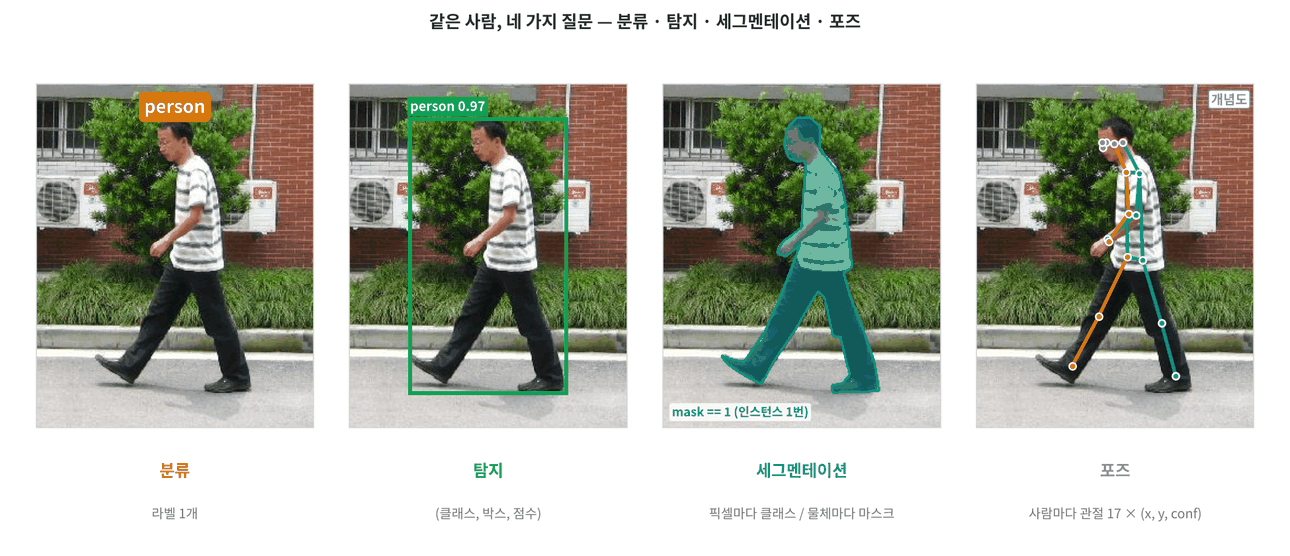

In [ ]:
#@title 🖼 그림 — 같은 사람의 분류 · 탐지 · 세그멘테이션 · 포즈 출력
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f1_box_mask_pose.png", embed=True, width=860))

**문제 1-1** Penn-Fudan 마스크 PNG 를 읽으세요. 픽셀값이 0 = 배경, 1, 2, … = 사람 번호 (**인스턴스**) 입니다. 사람마다 True/False 마스크로 나누고, 마스크의 경계 박스가 어노테이션 박스와 같은지 확인합니다. (PNG 를 `cv2.imread(..., 0)` 로 읽으면 값이 바뀔 수 있어 PIL 로 읽습니다.)

In [ ]:
m0 = np.array(Image.open(mask_path(img_paths[0])))
ids = np.unique(m0)                                       # [0, 1, 2]
inst = [m0 == k for k in ids[____]]                        # 배경(0) 빼고 사람마다
def mask_box(m):
    ys, xs = np.where(m)
    return np.array([xs.min(), ys.min(), xs.____, ys.max()], float)
print("픽셀값:", ids, "| 사람", len(inst), "명 | 픽셀 수", [int(m.sum()) for m in inst])
print("마스크 박스", [mask_box(m) for m in inst], "\n어노테이션", gts[0])
show([load_rgb(img_paths[0]), m0 * 120], ["image", "mask PNG (ids x 120)"], cols=2, size=4)

In [ ]:
assert ids.tolist() == [0, 1, 2] and len(inst) == 2
assert all(np.abs(mask_box(m) - g).max() <= 1 for m, g in zip(inst, gts[0])); print("✅")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACm0wID0gbnAuYXJyYXkoSW1hZ2Uub3BlbihtYXNrX3BhdGgoaW1nX3Bh"
    "dGhzWzBdKSkpCmlkcyA9IG5wLnVuaXF1ZShtMCkgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAjIFswLCAxLCAyXQppbnN0ID0gW20wID09IGsgZm9yIGsgaW4gaWRzWzE6XV0gICAgICAgICAgICAgICAgICAg"
    "ICAgICAjIOuwsOqyvSgwKSDrubzqs6Ag7IKs656M66eI64ukCmRlZiBtYXNrX2JveChtKToKICAgIHlzLCB4cyA9"
    "IG5wLndoZXJlKG0pCiAgICByZXR1cm4gbnAuYXJyYXkoW3hzLm1pbigpLCB5cy5taW4oKSwgeHMubWF4KCksIHlz"
    "Lm1heCgpXSwgZmxvYXQpCnByaW50KCLtlL3shYDqsJI6IiwgaWRzLCAifCDsgqzrnowiLCBsZW4oaW5zdCksICLr"
    "qoUgfCDtlL3shYAg7IiYIiwgW2ludChtLnN1bSgpKSBmb3IgbSBpbiBpbnN0XSkKcHJpbnQoIuuniOyKpO2BrCDr"
    "sJXsiqQiLCBbbWFza19ib3gobSkgZm9yIG0gaW4gaW5zdF0sICJcbuyWtOuFuO2FjOydtOyFmCIsIGd0c1swXSkK"
    "c2hvdyhbbG9hZF9yZ2IoaW1nX3BhdGhzWzBdKSwgbTAgKiAxMjBdLCBbImltYWdlIiwgIm1hc2sgUE5HIChpZHMg"
    "eCAxMjApIl0sIGNvbHM9Miwgc2l6ZT00KQoK8J+SoSDtlbTshKQK66eI7Iqk7YGsIOuwleyKpOuKlCBbMTU5LCAx"
    "ODEsIDMwMSwgNDMwXSwg7Ja064W47YWM7J207IWY7J2AIFsxNjAsIDE4MiwgMzAyLCA0MzFdIOKAlCAxIOywqOyd"
    "tOuKlCDslrTrhbjthYzsnbTshZjsnbQg7KKM7ZGc66W8IDHrtoDthLAg7IS46riwIOuVjOusuCAoRGF5IDQgMeq1"
    "kOyLnCAnVG9wIGxlZnQgcGl4ZWwgY28tb3JkaW5hdGVzIDogKDEsIDEpJykuIOqwmeydgCDrjbDsnbTthLDrnbzr"
    "j4Qg7KKM7ZGcIOq3nOy5meydhCDtmZXsnbjtlZjripQg7Iq16rSA7J20IO2VhOyalO2VqeuLiOuLpC4="
).decode("utf-8"))

**문제 1-2** 박스 안에서 실제 사람 픽셀이 차지하는 비율을 423명 전체에 대해 구하세요. 사람 k 번 마스크 ↔ 어노테이션 k 번째 박스가 짝입니다.

In [ ]:
fills = []
for p, g in zip(img_paths, gts):
    m = np.array(Image.open(mask_path(p)))
    for k, b in enumerate(g, start=1):
        x1, y1, x2, y2 = (b - 1).astype(int)                  # 1부터 센 좌표 → 0부터
        box_area = (x2 - x1 + 1) * (y2 - y1 + 1)
        fills.append((m[y1:y2 + 1, x1:x2 + 1] == ____).sum() / ____)
fills = np.array(fills)
print(f"{len(fills)}명 | 박스 중 사람 픽셀 비율 평균 {fills.mean():.4f} (최소 {fills.min():.2f}, 최대 {fills.max():.2f})")
plt.figure(figsize=(5, 3)); plt.hist(fills, bins=20); plt.xlabel("person pixels / box area"); plt.ylabel("people"); plt.show()

In [ ]:
assert len(fills) == 423 and 0.3 < fills.mean() < 0.9; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACmZpbGxzID0gW10KZm9yIHAsIGcgaW4gemlwKGltZ19wYXRocywgZ3Rz"
    "KToKICAgIG0gPSBucC5hcnJheShJbWFnZS5vcGVuKG1hc2tfcGF0aChwKSkpCiAgICBmb3IgaywgYiBpbiBlbnVt"
    "ZXJhdGUoZywgc3RhcnQ9MSk6CiAgICAgICAgeDEsIHkxLCB4MiwgeTIgPSAoYiAtIDEpLmFzdHlwZShpbnQpICAg"
    "ICAgICAgICAgICAgICAgIyAx67aA7YSwIOyEvCDsooztkZwg4oaSIDDrtoDthLAKICAgICAgICBib3hfYXJlYSA9"
    "ICh4MiAtIHgxICsgMSkgKiAoeTIgLSB5MSArIDEpCiAgICAgICAgZmlsbHMuYXBwZW5kKChtW3kxOnkyICsgMSwg"
    "eDE6eDIgKyAxXSA9PSBrKS5zdW0oKSAvIGJveF9hcmVhKQpmaWxscyA9IG5wLmFycmF5KGZpbGxzKQpwcmludChm"
    "IntsZW4oZmlsbHMpfeuqhSB8IOuwleyKpCDspJEg7IKs656MIO2UveyFgCDruYTsnKgg7Y+J6regIHtmaWxscy5t"
    "ZWFuKCk6LjRmfSAo7LWc7IaMIHtmaWxscy5taW4oKTouMmZ9LCDstZzrjIAge2ZpbGxzLm1heCgpOi4yZn0pIikK"
    "cGx0LmZpZ3VyZShmaWdzaXplPSg1LCAzKSk7IHBsdC5oaXN0KGZpbGxzLCBiaW5zPTIwKTsgcGx0LnhsYWJlbCgi"
    "cGVyc29uIHBpeGVscyAvIGJveCBhcmVhIik7IHBsdC55bGFiZWwoInBlb3BsZSIpOyBwbHQuc2hvdygpCgrwn5Kh"
    "IO2VtOyEpArsi6Ttlokg7JiIOiDtj4nqt6AgMC41MDM2IOKAlCDrsJXsiqTsnZgg7JW9IOygiOuwmCDqsIDquYzs"
    "nbTripQg67Cw6rK97J6F64uI64ukLiDtjJTri6Trpqzrpbwg67KM66as66m0IOu5hOycqOydgCDrjZQg65ao7Ja0"
    "7KeR64uI64ukLiAn67CV7Iqk6rCAIOychO2XmOq1rOyXrSDshKDsl5Ag64u/7JWY64ukJyDripQgJ+uquOydtCDr"
    "i7/slZjri6QnIOyZgCDri6TrpoXri4jri6Qg4oaSIOqyveqzhCDtjJDsoJXsl5DripQg66eI7Iqk7YGs64KYIOuw"
    "nCDsnITsuZggKDfqtZDsi5wpIOulvCDslIHri4jri6Qu"
).decode("utf-8"))

**문제 1-3** 박스의 세로/가로 비율 (h/w) 로 '쓰러짐' 을 판정할 수 있을까요? 서 있는 사람들의 비율 분포를 보고, 사진을 90° 돌리면 (누운 사람 흉내) 비율이 어떻게 되는지 계산하세요.

In [ ]:
all_boxes = np.concatenate(gts)
ar = (all_boxes[:, 3] - all_boxes[:, 1]) / (all_boxes[:, 2] - all_boxes[:, 0])     # h / w
ar_rot = ____                                          # 90° 돌리면 가로 · 세로가 바뀜
print(f"서 있음 h/w 평균 {ar.mean():.2f} (최소 {ar.min():.2f}) | 90° 회전 h/w 평균 {ar_rot.mean():.2f}")
print("h/w < 1 인 '서 있는' 사람:", int((ar ____ 1).sum()), "명")

In [ ]:
assert np.isclose(ar_rot.mean(), (1 / ar).mean()) and ar.mean() > 1.5; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTMg4pSA4pSACmFsbF9ib3hlcyA9IG5wLmNvbmNhdGVuYXRlKGd0cykKYXIgPSAoYWxs"
    "X2JveGVzWzosIDNdIC0gYWxsX2JveGVzWzosIDFdKSAvIChhbGxfYm94ZXNbOiwgMl0gLSBhbGxfYm94ZXNbOiwg"
    "MF0pICAgICAjIGggLyB3CmFyX3JvdCA9IDEgLyBhciAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICMgOTDCsCDrj4zrpqzrqbQg6rCA66GcIMK3IOyEuOuhnOqwgCDrsJTrgJwKcHJpbnQoZiLshJwg7J6I"
    "7J2MIGgvdyDtj4nqt6Age2FyLm1lYW4oKTouMmZ9ICjstZzshowge2FyLm1pbigpOi4yZn0pIHwgOTDCsCDtmozs"
    "oIQgaC93IO2Pieq3oCB7YXJfcm90Lm1lYW4oKTouMmZ9IikKcHJpbnQoImgvdyA8IDEg7J24ICfshJwg7J6I64qU"
    "JyDsgqzrnow6IiwgaW50KChhciA8IDEpLnN1bSgpKSwgIuuqhSIpCgrwn5KhIO2VtOyEpArsi6Ttlokg7JiIOiDs"
    "hJwg7J6I64qUIOyCrOuejCBoL3cg7Y+J6regIDIuNzcuIOuIhOyasOuptCAxIOyVhOuemOuhnCDrgrTroKTqsIDr"
    "i4gg6rec7LmZICdoL3cgPCAxIOKGkiDsk7Drn6zsp5AnIOydtCDqt7jrn7Trk6/tlbQg67O07J207KeA66eMLCDt"
    "l4jrpqzrpbwg7IiZ7J206rGw64KYIOyqvOq3uOugpCDslYnsnLzrqbQgwrcg7Lm066mU65286rCAIOychOyXkOyE"
    "nCDrgrTroKTri6Trs7TrqbQgwrcg7IKs656M7J20IOqwgOugpCDrqrgg7J2867aA66eMIOyeoe2eiOuptCDruYTs"
    "nKjsnbQg7Im96rKMIOuwlOuAneuLiOuLpC4gM+q1kOyLnOyXkCAqKuq0gOygiCAo7Y+s7KaIKSoqIOuhnCDrjZQg"
    "66+/7J2EIOunjO2VnCDqt5zsuZnsnYQg66eM65Ot64uI64ukLg=="
).decode("utf-8"))

#### 📌 1교시 정리

- 박스 안 약 절반은 배경 → 경계 · 넓이 문제는 세그멘테이션.
- 박스 비율로 쓰러짐 판정은 자세 · 시점에 약함 → 포즈.
- Penn-Fudan 마스크 PNG: 0 = 배경, k = k번째 사람 (인스턴스).

## 2교시 — 세그멘테이션: Encoder-Decoder · mIoU

| | **semantic** | **instance** |
|---|---|---|
| 출력 | 픽셀마다 클래스 (H×W 라벨 지도) | 물체마다 마스크 + 클래스 + 점수 |
| 같은 클래스 두 사람 | 구분 안 함 (모두 'person') | 따로 (사람 1, 사람 2) |
| 대표 모델 | FCN · U-Net · **DeepLabV3** | Mask R-CNN · **YOLOv8-seg** |

**Encoder-Decoder**: 인코더 (Day 2~3 의 CNN) 가 해상도를 줄이며 '무엇' 을 뽑고, 디코더가 해상도를 다시 키워 '어디' 를 픽셀 단위로 복원합니다. U-Net 은 인코더의 같은 해상도 특징을 디코더로 바로 넘기는 **skip connection** 으로 경계를 살립니다.

**해상도 키우기**: (1) Bilinear upsample (학습 파라미터 없음) + Conv, (2) **Transposed Conv** (학습하는 upsampling).

$$\text{출력 크기} = (\text{입력} - 1) \times s - 2p + k$$

> 🎬 **애니메이션** [D5-2 Encoder-Decoder 와 mIoU](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

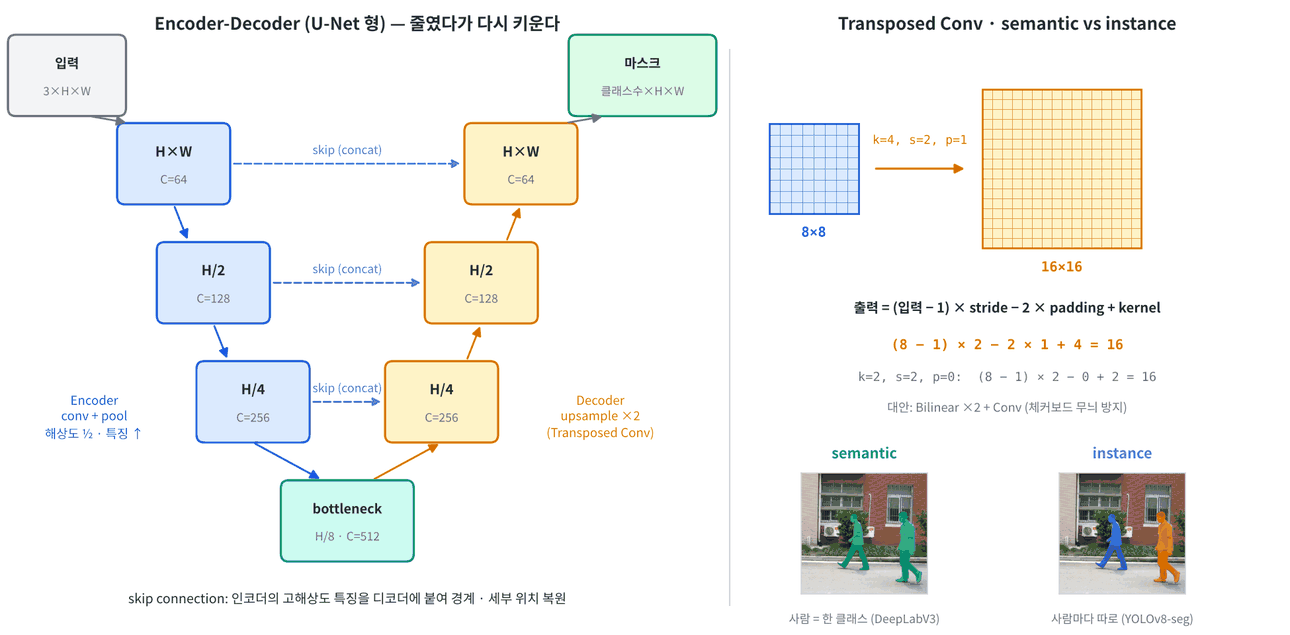

In [ ]:
#@title 🖼 그림 — Encoder-Decoder 구조와 Transposed Conv
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f2_encoder_decoder.png", embed=True, width=860))

**문제 2-1** Transposed Conv 출력 크기 공식 `tconv_out` 을 완성하고 `nn.ConvTranspose2d` 의 실제 출력과 비교하세요.

In [ ]:
def tconv_out(n, k, s, p):
    return (____) * s - 2 * p + ____

x8 = torch.randn(1, 64, 8, 8)
for k, s, p in [(4, 2, 1), (2, 2, 0), (3, 2, 1), (3, 1, 1)]:
    y = nn.ConvTranspose2d(64, 32, kernel_size=k, stride=s, padding=p)(x8)
    print(f"k={k} s={s} p={p}: 공식 {tconv_out(8, k, s, p)} | 실제 {tuple(y.shape[2:])}")
up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)(x8)
print("bilinear ×2:", tuple(up.shape[2:]))

In [ ]:
assert all(tconv_out(8, k, s, p) == nn.ConvTranspose2d(1, 1, k, s, p)(torch.zeros(1, 1, 8, 8)).shape[-1]
           for k, s, p in [(4, 2, 1), (2, 2, 0), (3, 2, 1), (3, 1, 1), (5, 3, 2)])
assert tconv_out(8, 4, 2, 1) == 16; print("✅")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmRlZiB0Y29udl9vdXQobiwgaywgcywgcCk6CiAgICByZXR1cm4gKG4g"
    "LSAxKSAqIHMgLSAyICogcCArIGsKCng4ID0gdG9yY2gucmFuZG4oMSwgNjQsIDgsIDgpCmZvciBrLCBzLCBwIGlu"
    "IFsoNCwgMiwgMSksICgyLCAyLCAwKSwgKDMsIDIsIDEpLCAoMywgMSwgMSldOgogICAgeSA9IG5uLkNvbnZUcmFu"
    "c3Bvc2UyZCg2NCwgMzIsIGtlcm5lbF9zaXplPWssIHN0cmlkZT1zLCBwYWRkaW5nPXApKHg4KQogICAgcHJpbnQo"
    "ZiJrPXtrfSBzPXtzfSBwPXtwfTog6rO17IudIHt0Y29udl9vdXQoOCwgaywgcywgcCl9IHwg7Iuk7KCcIHt0dXBs"
    "ZSh5LnNoYXBlWzI6XSl9IikKdXAgPSBubi5VcHNhbXBsZShzY2FsZV9mYWN0b3I9MiwgbW9kZT0iYmlsaW5lYXIi"
    "LCBhbGlnbl9jb3JuZXJzPUZhbHNlKSh4OCkKcHJpbnQoImJpbGluZWFyIMOXMjoiLCB0dXBsZSh1cC5zaGFwZVsy"
    "Ol0pKQoK8J+SoSDtlbTshKQKaz00LCBzPTIsIHA9MSDihpIgKDjiiJIxKcOXMiDiiJIgMiArIDQgPSAxNiDigJQg"
    "7KCV7ZmV7Z6IIDLrsLAuIENvbnYg7Lac66ClIO2BrOq4sCDqs7Xsi50gKERheSAyOiAobiArIDJwIOKIkiBrKS9z"
    "ICsgMSkg7J2EIOqxsOq+uOuhnCDtkbwg6rKD7J6F64uI64ukLiBrIOqwgCBzIOuhnCDrgpjriITslrTrlqjslrTs"
    "p4Dsp4Ag7JWK7Jy866m0IChrPTMsIHM9Mikg6rK57LmY64qUIOy5uOydtCDsg53qsqgg7LK07Luk67O065OcIOus"
    "tOuKrOqwgCDrgpjquLAg7Ims7JuMLCDsmpTsppjsnYAgYmlsaW5lYXIgKyBDb252IOulvCDrp47snbQg7JSB64uI"
    "64ukLg=="
).decode("utf-8"))

### 마스크 평가 — IoU · mIoU

Day 4 의 IoU 를 박스 대신 **픽셀 집합**으로: IoU = |A ∩ B| / |A ∪ B| (픽셀 수). **mIoU** = 클래스마다 IoU 를 구해 평균 (배경도 한 클래스).

손 계산 예 (4×4): 정답 사람 = 왼쪽 2열 (8픽셀), 예측 사람 = 왼쪽 3열 (12픽셀) → 사람 IoU 8/12 = 0.6667, 배경 IoU 4/8 = 0.5 → mIoU 0.5833.

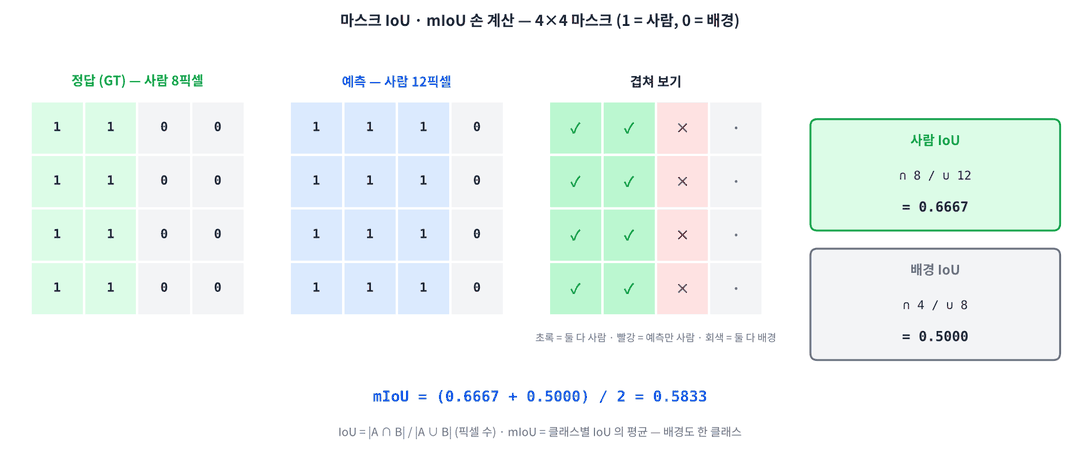

In [ ]:
#@title 🖼 그림 — 4×4 마스크 mIoU 손 계산
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f3_miou.png", embed=True, width=720))

**문제 2-2** 라벨 지도 (정수 배열) 두 개로 클래스별 IoU 와 mIoU 를 구하는 `miou` 를 완성하세요. 정답 · 예측 어디에도 없는 클래스는 NaN 으로 두고 평균에서 뺍니다.

In [ ]:
def miou(pred, gt, n_cls=2):
    ious = []
    for c in range(n_cls):
        p, g = (pred == c), (gt == c)
        union = (p | g).sum()
        ious.append((p ____ g).sum() / union if union > 0 else np.nan)
    ious = np.array(ious)
    return ious, float(np.____(ious))

gt4 = np.zeros((4, 4), int); gt4[:, :2] = 1
pr4 = np.zeros((4, 4), int); pr4[:, :3] = 1
print(miou(pr4, gt4))

In [ ]:
ious4, m4 = miou(pr4, gt4)
assert np.allclose(ious4, [0.5, 8 / 12]) and np.isclose(m4, 0.5833, atol=1e-4)
assert np.isnan(miou(np.zeros((2, 2), int), np.zeros((2, 2), int), 3)[0][2]); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRlZiBtaW91KHByZWQsIGd0LCBuX2Nscz0yKToKICAgIGlvdXMgPSBb"
    "XQogICAgZm9yIGMgaW4gcmFuZ2Uobl9jbHMpOgogICAgICAgIHAsIGcgPSAocHJlZCA9PSBjKSwgKGd0ID09IGMp"
    "CiAgICAgICAgdW5pb24gPSAocCB8IGcpLnN1bSgpCiAgICAgICAgaW91cy5hcHBlbmQoKHAgJiBnKS5zdW0oKSAv"
    "IHVuaW9uIGlmIHVuaW9uID4gMCBlbHNlIG5wLm5hbikKICAgIGlvdXMgPSBucC5hcnJheShpb3VzKQogICAgcmV0"
    "dXJuIGlvdXMsIGZsb2F0KG5wLm5hbm1lYW4oaW91cykpCgpndDQgPSBucC56ZXJvcygoNCwgNCksIGludCk7IGd0"
    "NFs6LCA6Ml0gPSAxCnByNCA9IG5wLnplcm9zKCg0LCA0KSwgaW50KTsgcHI0WzosIDozXSA9IDEKcHJpbnQobWlv"
    "dShwcjQsIGd0NCkp"
).decode("utf-8"))

### YOLOv8n-seg — 인스턴스 세그멘테이션

YOLOv8-seg 는 Day 4 의 탐지 head 에 **마스크 계수 32개**를 더 냅니다. 이미지 전체에 대한 **prototype 마스크 32장** (160×160) 을 계수로 섞어 (선형 결합 → sigmoid) 물체마다 마스크를 만들고, 박스 밖은 지웁니다. ultralytics 결과의 `r.masks.xy` 는 원본 좌표의 **다각형 (외곽선)** 목록이라 `cv2.fillPoly` 로 원본 크기 마스크를 바로 만들 수 있습니다.

**문제 2-3** YOLOv8n-seg 로 사람 마스크를 구해 **semantic 사람 마스크** (모든 사람의 합집합, 원본 크기) 를 만드는 `seg_person_mask` 를 완성하고, 첫 이미지에서 정답과 비교하세요.

In [ ]:
from ultralytics import YOLO
seg = YOLO("yolov8n-seg.pt")

def seg_person_mask(model, img_bgr, conf=0.25):
    H, W = img_bgr.shape[:2]
    r = model.predict(img_bgr, conf=conf, classes=[0], verbose=False)[0]
    pm = np.zeros((H, W), np.uint8)
    if r.masks is not None:
        for poly in r.masks.xy:                             # 사람마다 외곽선 (원본 좌표)
            if len(poly):
                cv2.fillPoly(pm, [poly.astype(np.int32)], ____)
    return pm, (0 if r.masks is None else len(r.masks))

img0 = cv2.imread(img_paths[0])
pm0, n0 = seg_person_mask(seg, img0)
gt0 = (np.array(Image.open(mask_path(img_paths[0]))) ____ 0).astype(int)
ious0, m0iou = miou(pm0, gt0)
print(f"인스턴스 {n0}개 | 배경 IoU {ious0[0]:.4f} · 사람 IoU {ious0[1]:.4f} · mIoU {m0iou:.4f}")
over = load_rgb(img_paths[0]).copy(); over[pm0 > 0] = (0.5 * over[pm0 > 0] + [0, 0, 127]).astype(np.uint8)
show([over, gt0 * 255, pm0 * 255], ["YOLOv8n-seg overlay", "GT person mask", "pred person mask"], cols=3, size=3.8)

In [ ]:
assert pm0.shape == gt0.shape and n0 >= 2 and ious0[1] > 0.6; print("✅")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACmZyb20gdWx0cmFseXRpY3MgaW1wb3J0IFlPTE8Kc2VnID0gWU9MTygi"
    "eW9sb3Y4bi1zZWcucHQiKQoKZGVmIHNlZ19wZXJzb25fbWFzayhtb2RlbCwgaW1nX2JnciwgY29uZj0wLjI1KToK"
    "ICAgIEgsIFcgPSBpbWdfYmdyLnNoYXBlWzoyXQogICAgciA9IG1vZGVsLnByZWRpY3QoaW1nX2JnciwgY29uZj1j"
    "b25mLCBjbGFzc2VzPVswXSwgdmVyYm9zZT1GYWxzZSlbMF0KICAgIHBtID0gbnAuemVyb3MoKEgsIFcpLCBucC51"
    "aW50OCkKICAgIGlmIHIubWFza3MgaXMgbm90IE5vbmU6CiAgICAgICAgZm9yIHBvbHkgaW4gci5tYXNrcy54eTog"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICMg7IKs656M66eI64ukIOyZuOqzveyEoCAo7JuQ67O4IOyijO2R"
    "nCkKICAgICAgICAgICAgaWYgbGVuKHBvbHkpOgogICAgICAgICAgICAgICAgY3YyLmZpbGxQb2x5KHBtLCBbcG9s"
    "eS5hc3R5cGUobnAuaW50MzIpXSwgMSkKICAgIHJldHVybiBwbSwgKDAgaWYgci5tYXNrcyBpcyBOb25lIGVsc2Ug"
    "bGVuKHIubWFza3MpKQoKaW1nMCA9IGN2Mi5pbXJlYWQoaW1nX3BhdGhzWzBdKQpwbTAsIG4wID0gc2VnX3BlcnNv"
    "bl9tYXNrKHNlZywgaW1nMCkKZ3QwID0gKG5wLmFycmF5KEltYWdlLm9wZW4obWFza19wYXRoKGltZ19wYXRoc1sw"
    "XSkpKSA+IDApLmFzdHlwZShpbnQpCmlvdXMwLCBtMGlvdSA9IG1pb3UocG0wLCBndDApCnByaW50KGYi7J247Iqk"
    "7YS07IqkIHtuMH3qsJwgfCDrsLDqsr0gSW9VIHtpb3VzMFswXTouNGZ9IMK3IOyCrOuejCBJb1Uge2lvdXMwWzFd"
    "Oi40Zn0gwrcgbUlvVSB7bTBpb3U6LjRmfSIpCm92ZXIgPSBsb2FkX3JnYihpbWdfcGF0aHNbMF0pLmNvcHkoKTsg"
    "b3ZlcltwbTAgPiAwXSA9ICgwLjUgKiBvdmVyW3BtMCA+IDBdICsgWzAsIDAsIDEyN10pLmFzdHlwZShucC51aW50"
    "OCkKc2hvdyhbb3ZlciwgZ3QwICogMjU1LCBwbTAgKiAyNTVdLCBbIllPTE92OG4tc2VnIG92ZXJsYXkiLCAiR1Qg"
    "cGVyc29uIG1hc2siLCAicHJlZCBwZXJzb24gbWFzayJdLCBjb2xzPTMsIHNpemU9My44KQoK8J+SoSDtlbTshKQK"
    "7KCV64u1IOuniOyKpO2BrOuKlCDsgqzrnowg67KI7Zi466W8IOuLtOqzoCDsnojslrQgYD4gMGAg7Jy866GcIOyC"
    "rOuejCAvIOuwsOqyvSDrkZAg7YG0656Y7Iqk66GcIOuwlOq/qOyKteuLiOuLpCAoc2VtYW50aWMpLiDsmIjsuKHs"
    "nYAg7IKs656M66eI64ukIOuLpOqwge2YleydhCDqsJnsnYAg6rCSIDEg66GcIOyxhOybjCDtlansp5HtlansnYQg"
    "66eM65Ok7JeI7Iq164uI64ukLiDqsr3qs4Qg67aA67aEIMK3IOuLpOumrCDsgqzsnbQg7YuI7J20IOyjvOuhnCDt"
    "i4Drpr3ri4jri6Qg4oCUIOuniOyKpO2BrOuKlCAxNjDDlzE2MCBwcm90b3R5cGUg7JeQ7IScIO2CpOyatCDqsoPs"
    "nbTrnbwg6rK96rOE6rCAIOu2gOuTnOufveyKteuLiOuLpC4="
).decode("utf-8"))

**문제 2-4** Penn-Fudan 170장 전체의 mIoU 를 구하세요. 이미지마다 평균을 내지 않고, **모든 이미지의 교집합 · 합집합 픽셀 수를 클래스별로 누적**해 마지막에 나눕니다 (큰 이미지 · 작은 이미지를 공정하게).

In [ ]:
inter_sum, union_sum = np.zeros(2), np.zeros(2)
t0 = time.perf_counter()
for p in img_paths:
    pm, _ = seg_person_mask(seg, cv2.imread(p))
    g = (np.array(Image.open(mask_path(p))) > 0).astype(int)
    for c in range(2):
        inter_sum[c] += ((pm == c) & (g == c)).sum()
        union_sum[c] += ((pm == c) ____ (g == c)).sum()
seg_ious = inter_sum / ____
seg_ms = (time.perf_counter() - t0) / len(img_paths) * 1000
print(f"배경 IoU {seg_ious[0]:.4f} · 사람 IoU {seg_ious[1]:.4f} → mIoU {seg_ious.mean():.4f} | {seg_ms:.0f} ms/장 ({device})")

In [ ]:
assert seg_ious.shape == (2,) and seg_ious.mean() > 0.7 and seg_ious[0] > seg_ious[1]; print("✅")

In [ ]:
#@title 🔒 정답 보기 2-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTQg4pSA4pSACmludGVyX3N1bSwgdW5pb25fc3VtID0gbnAuemVyb3MoMiksIG5wLnpl"
    "cm9zKDIpCnQwID0gdGltZS5wZXJmX2NvdW50ZXIoKQpmb3IgcCBpbiBpbWdfcGF0aHM6CiAgICBwbSwgXyA9IHNl"
    "Z19wZXJzb25fbWFzayhzZWcsIGN2Mi5pbXJlYWQocCkpCiAgICBnID0gKG5wLmFycmF5KEltYWdlLm9wZW4obWFz"
    "a19wYXRoKHApKSkgPiAwKS5hc3R5cGUoaW50KQogICAgZm9yIGMgaW4gcmFuZ2UoMik6CiAgICAgICAgaW50ZXJf"
    "c3VtW2NdICs9ICgocG0gPT0gYykgJiAoZyA9PSBjKSkuc3VtKCkKICAgICAgICB1bmlvbl9zdW1bY10gKz0gKChw"
    "bSA9PSBjKSB8IChnID09IGMpKS5zdW0oKQpzZWdfaW91cyA9IGludGVyX3N1bSAvIHVuaW9uX3N1bQpzZWdfbXMg"
    "PSAodGltZS5wZXJmX2NvdW50ZXIoKSAtIHQwKSAvIGxlbihpbWdfcGF0aHMpICogMTAwMApwcmludChmIuuwsOqy"
    "vSBJb1Uge3NlZ19pb3VzWzBdOi40Zn0gwrcg7IKs656MIElvVSB7c2VnX2lvdXNbMV06LjRmfSDihpIgbUlvVSB7"
    "c2VnX2lvdXMubWVhbigpOi40Zn0gfCB7c2VnX21zOi4wZn0gbXMv7J6lICh7ZGV2aWNlfSkiKQoK8J+SoSDtlbTs"
    "hKQK7Iuk7ZaJIOyYiDog67Cw6rK9IDAuOTQyNSDCtyDsgqzrnowgMC43NjgyIOKGkiBtSW9VIDAuODU1My4g67Cw"
    "6rK9IElvVSDqsIAg64aS7J2AIOqyg+ydgCDrsLDqsr0g7ZS97IWA7J20IO2bqOyUrCDrp47slYTshJzsnoXri4jr"
    "i6Qg4oCUIO2BtOuemOyKpCDrtojqt6DtmJXsnbQg7YGs66m0ICoq6rSA7IusIO2BtOuemOyKpCAo7IKs656MKSBJ"
    "b1UqKiDrpbwg65Sw66GcIOu0kOyVvCDtlanri4jri6QuIFBlbm4tRnVkYW4g7KCV64u17JeQIOyXhuuKlCDsnpHs"
    "nYAg7IKs656M7J2EIOuqqOuNuOydtCDssL7snLzrqbQg7IKs656MIElvVSDqsIAg64K066Ck6rCR64uI64ukIChE"
    "YXkgNCDsmYAg6rCZ7J2AIOydtOyVvOq4sCku"
).decode("utf-8"))

### (선택) semantic 세그멘테이션 — DeepLabV3-MobileNetV3

torchvision 의 DeepLabV3 는 **픽셀마다 21 클래스** (Pascal VOC, 15 = person) 점수를 냅니다. 사람이 몇 명인지는 모르지만 '사람 영역' 은 알려 줍니다. Colab 에서 실행해 보세요 (가중치 약 40 MB). 채점과는 관계없습니다.

In [ ]:
try:
    from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large
    dl = deeplabv3_mobilenet_v3_large(weights="DEFAULT").eval().to(device)
    tf = torchvision.transforms.Compose([torchvision.transforms.ToTensor(),
                                         torchvision.transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
    with torch.no_grad():
        o = dl(tf(load_rgb(img_paths[0]))[None].to(device))["out"][0]         # (21, H, W)
    lab = o.argmax(0).cpu().numpy()
    print("DeepLabV3 출력", tuple(o.shape), "| 사람 IoU", round(miou((lab == 15).astype(int), gt0)[0][1], 4))
    show([load_rgb(img_paths[0]), (lab == 15) * 255], ["image", "DeepLabV3: person pixels"], cols=2, size=4)
except Exception as e:
    print("DeepLabV3 를 불러오지 못했습니다 (선택 실습):", e)

#### 📌 2교시 정리

- semantic = 픽셀마다 클래스, instance = 물체마다 마스크.
- Encoder-Decoder + skip. Transposed Conv 출력 = (n−1)s − 2p + k.
- mIoU = 클래스별 픽셀 IoU 평균. 데이터 전체는 교집합 · 합집합을 누적해서.

## 3교시 — 포즈 추정: 관절 · 쓰러짐 규칙

**COCO 17 관절**: 0 코 · 1–2 눈 · 3–4 귀 · **5–6 어깨** · 7–8 팔꿈치 · 9–10 손목 · **11–12 엉덩이** · 13–14 무릎 · 15–16 발목 (홀수 = 왼쪽, 짝수 = 오른쪽 — 사진 속 사람 기준).

| 방식 | 하는 일 | 예 | 특징 |
|---|---|---|---|
| **top-down** | 사람 박스 먼저 → 박스마다 관절 | Keypoint R-CNN · HRNet | 정확, 사람 수만큼 느려짐 |
| **bottom-up** | 관절 먼저 다 찾고 → 사람별로 묶기 | OpenPose | 사람 수와 무관 |
| **1-stage** | 칸마다 박스 + 관절 17개를 한 번에 | **YOLOv8-pose** | 빠름, 사람 수와 무관 |

관절 위치를 찾는 방법: **heatmap** (관절마다 확률 지도 → 최댓값 위치, HRNet) 또는 **직접 회귀** (좌표를 숫자로, YOLOv8-pose).

> 🎬 **애니메이션** [D5-3 관절과 쓰러짐 규칙](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
KPT = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder", "left_elbow",
       "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"]
SKELETON = [(5, 6), (5, 7), (7, 9), (6, 8), (8, 10), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 5), (0, 6)]

def draw_pose(img, kpts, confs, min_conf=0.5):
    out = img.copy()
    for kp, cf in zip(kpts, confs):
        for a, b in SKELETON:
            if cf[a] >= min_conf and cf[b] >= min_conf:
                cv2.line(out, tuple(int(v) for v in kp[a]), tuple(int(v) for v in kp[b]), (0, 200, 255), 2)
        for (x, y), c in zip(kp, cf):
            if c >= min_conf: cv2.circle(out, (int(x), int(y)), 3, (255, 0, 0), -1)
    return out

**문제 3-1** YOLOv8n-pose 로 관절을 찾으세요. 결과 `r.keypoints.xy` 는 (사람 수, 17, 2) 좌표, `r.keypoints.conf` 는 (사람 수, 17) 신뢰도입니다.

In [ ]:
pose = YOLO("yolov8n-pose.pt")
def run_pose(model, img_bgr, conf=0.25):
    r = model.predict(img_bgr, conf=conf, verbose=False)[0]
    return r.keypoints.xy.cpu().numpy(), r.keypoints.____.cpu().numpy(), r.boxes.xyxy.cpu().numpy()

k0, c0, b0 = run_pose(pose, img0)
kv, cv_, bv = run_pose(pose, ____)
print("사진:", k0.shape, "| 영상 프레임 200:", kv.shape)
print("첫 사람 어깨 (5, 6):", k0[0, 5], k0[0, 6], "| conf", c0[0, [5, 6]].round(2))
show([draw_pose(load_rgb(img_paths[0]), k0, c0), draw_pose(frame200[..., ::-1], kv, cv_)], ["Penn-Fudan", "video frame 200"], cols=2, size=4.5)

In [ ]:
assert k0.ndim == 3 and k0.shape[1:] == (17, 2) and c0.shape == k0.shape[:2] and len(k0) >= 2; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACnBvc2UgPSBZT0xPKCJ5b2xvdjhuLXBvc2UucHQiKQpkZWYgcnVuX3Bv"
    "c2UobW9kZWwsIGltZ19iZ3IsIGNvbmY9MC4yNSk6CiAgICByID0gbW9kZWwucHJlZGljdChpbWdfYmdyLCBjb25m"
    "PWNvbmYsIHZlcmJvc2U9RmFsc2UpWzBdCiAgICByZXR1cm4gci5rZXlwb2ludHMueHkuY3B1KCkubnVtcHkoKSwg"
    "ci5rZXlwb2ludHMuY29uZi5jcHUoKS5udW1weSgpLCByLmJveGVzLnh5eHkuY3B1KCkubnVtcHkoKQoKazAsIGMw"
    "LCBiMCA9IHJ1bl9wb3NlKHBvc2UsIGltZzApCmt2LCBjdl8sIGJ2ID0gcnVuX3Bvc2UocG9zZSwgZnJhbWUyMDAp"
    "CnByaW50KCLsgqzsp4Q6IiwgazAuc2hhcGUsICJ8IOyYgeyDgSDtlITroIjsnoQgMjAwOiIsIGt2LnNoYXBlKQpw"
    "cmludCgi7LKrIOyCrOuejCDslrTquaggKDUsIDYpOiIsIGswWzAsIDVdLCBrMFswLCA2XSwgInwgY29uZiIsIGMw"
    "WzAsIFs1LCA2XV0ucm91bmQoMikpCnNob3coW2RyYXdfcG9zZShsb2FkX3JnYihpbWdfcGF0aHNbMF0pLCBrMCwg"
    "YzApLCBkcmF3X3Bvc2UoZnJhbWUyMDBbLi4uLCA6Oi0xXSwga3YsIGN2XyldLCBbIlBlbm4tRnVkYW4iLCAidmlk"
    "ZW8gZnJhbWUgMjAwIl0sIGNvbHM9Miwgc2l6ZT00LjUpCgrwn5KhIO2VtOyEpApjb25mIOqwgCDrgq7snYAg6rSA"
    "7KCIICjqsIDroKTsp4Qg7YyUIMK3IO2ZlOuptCDrsJYg67Cc66qpKSDsnYAg6re466as7KeAIOyViuyVmOyKteuL"
    "iOuLpC4g6rec7LmZ7J2EIOunjOuTpCDrlYzrj4QgKipjb25mIOqwgCDrgq7snYAg6rSA7KCI7J2AIOuvv+yngCDs"
    "lYrripQg6rKDKirsnbQg7KSR7JqU7ZWp64uI64ukLg=="
).decode("utf-8"))

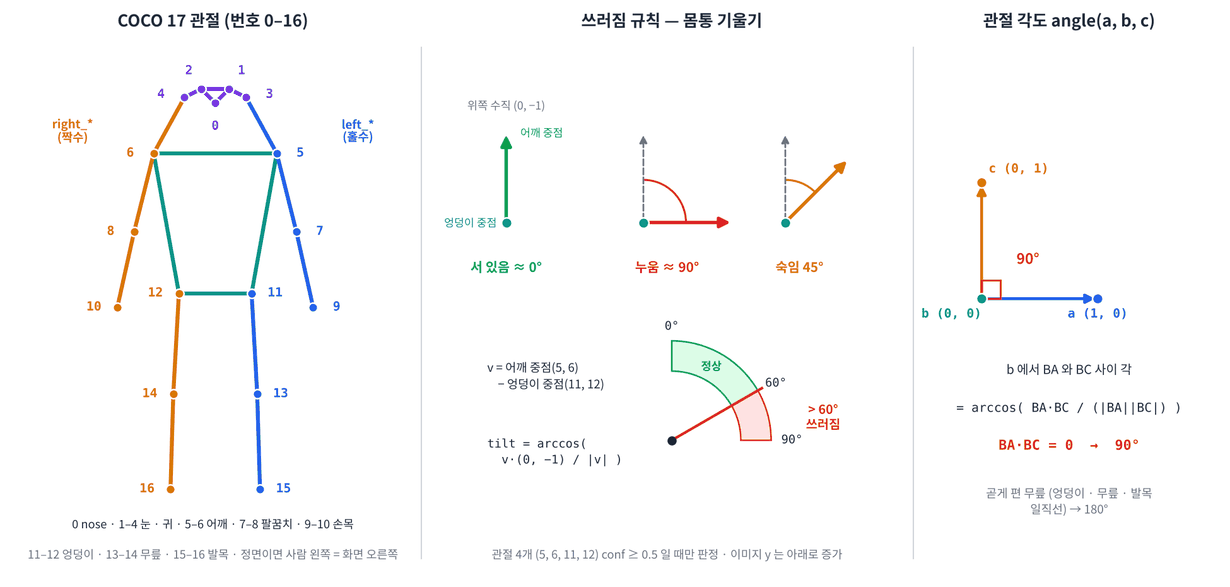

In [ ]:
#@title 🖼 그림 — COCO 17 관절과 몸통 기울기 규칙
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f4_pose_rule.png", embed=True, width=820))

**문제 3-2** 세 점 a, b, c 에서 **b 의 각도** (BA 와 BC 사이) 를 구하는 `angle` 을 완성하세요. 무릎 각도 (엉덩이 · 무릎 · 발목) 같은 관절 각도에 씁니다.

In [ ]:
def angle(a, b, c):
    ba, bc = np.asarray(a, float) - np.asarray(b, float), np.asarray(c, float) - np.asarray(b, float)
    cos = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(____) + 1e-9)
    return float(np.degrees(np.arccos(np.clip(cos, ____, 1))))

print(angle((1, 0), (0, 0), (0, 1)), angle((0, 0), (0, 1), (0, 2)))
p0 = k0[0]
print(f"첫 사람 왼쪽 무릎 각도 {angle(p0[11], p0[13], p0[15]):.1f}° · 오른쪽 {angle(p0[12], p0[14], p0[16]):.1f}°")

In [ ]:
assert np.isclose(angle((1, 0), (0, 0), (0, 1)), 90) and np.isclose(angle((0, 0), (0, 1), (0, 2)), 180, atol=1e-3); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmRlZiBhbmdsZShhLCBiLCBjKToKICAgIGJhLCBiYyA9IG5wLmFzYXJy"
    "YXkoYSwgZmxvYXQpIC0gbnAuYXNhcnJheShiLCBmbG9hdCksIG5wLmFzYXJyYXkoYywgZmxvYXQpIC0gbnAuYXNh"
    "cnJheShiLCBmbG9hdCkKICAgIGNvcyA9IG5wLmRvdChiYSwgYmMpIC8gKG5wLmxpbmFsZy5ub3JtKGJhKSAqIG5w"
    "LmxpbmFsZy5ub3JtKGJjKSArIDFlLTkpCiAgICByZXR1cm4gZmxvYXQobnAuZGVncmVlcyhucC5hcmNjb3MobnAu"
    "Y2xpcChjb3MsIC0xLCAxKSkpKQoKcHJpbnQoYW5nbGUoKDEsIDApLCAoMCwgMCksICgwLCAxKSksIGFuZ2xlKCgw"
    "LCAwKSwgKDAsIDEpLCAoMCwgMikpKQpwMCA9IGswWzBdCnByaW50KGYi7LKrIOyCrOuejCDsmbzsqr0g66y066aO"
    "IOqwgeuPhCB7YW5nbGUocDBbMTFdLCBwMFsxM10sIHAwWzE1XSk6LjFmfcKwIMK3IOyYpOuluOyqvSB7YW5nbGUo"
    "cDBbMTJdLCBwMFsxNF0sIHAwWzE2XSk6LjFmfcKwIikKCvCfkqEg7ZW07ISkCmBucC5jbGlwKGNvcywgLTEsIDEp"
    "YCDsnYAg67aA64+Z7IaM7IiYIOyYpOywqOuhnCAxLjAwMDAwMDEg7J20IOuQmOyWtCBhcmNjb3Mg6rCAIE5hTiDs"
    "nbQg65CY64qUIOqyg+ydhCDrp4nsirXri4jri6QuIOqxt+uKlCDsgqzrnozsnZgg66y066aO7J2AIDE1MH4xODDC"
    "sCDqt7zsspgsIOyqvOq3uOugpCDslYnsnLzrqbQgOTDCsCDslYTrnpjroZwg64K066Ck6rCR64uI64ukLg=="
).decode("utf-8"))

**문제 3-3** **쓰러짐 규칙**을 만드세요.

- 몸통 기울기 `body_tilt` = 엉덩이 중점 (11, 12) → 어깨 중점 (5, 6) 벡터와 **위쪽 수직 (0, −1)** 사이 각도 (이미지 y 는 아래로 증가)
- `is_fallen` = 기울기 > 60° 이면 True. 단, 어깨 · 엉덩이 4개 관절 conf 가 모두 0.5 이상일 때만 판정하고, 아니면 None (판정 보류)

넘어진 사람 영상이 없어 사진을 **90° 회전**해서 '누운 사람' 을 흉내 냅니다.

In [ ]:
def body_tilt(kpts):
    shoulder = (kpts[5] + kpts[6]) / 2
    hip = (kpts[11] + kpts[12]) / 2
    return angle(hip + np.array([0, ____]), hip, shoulder)          # 위쪽 수직과 몸통 사이 각

def is_fallen(kpts, conf, thr=60, min_conf=0.5):
    if conf[[5, 6, 11, 12]].min() < ____:
        return None
    return body_tilt(kpts) > ____

def biggest(b):                                                     # 가장 큰 사람 (주인공)
    return int(np.argmax((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])))

img_rot = cv2.rotate(img0, cv2.ROTATE_90_CLOCKWISE)
kr, cr, br = run_pose(pose, img_rot)
i_up, i_rot = biggest(b0), biggest(br)
tilt_up, tilt_rot = body_tilt(k0[i_up]), body_tilt(kr[i_rot])
print(f"원본: 기울기 {tilt_up:.1f}° → 쓰러짐 {is_fallen(k0[i_up], c0[i_up])}")
print(f"90° 회전: 기울기 {tilt_rot:.1f}° → 쓰러짐 {is_fallen(kr[i_rot], cr[i_rot])}")
show([draw_pose(load_rgb(img_paths[0]), k0[i_up:i_up + 1], c0[i_up:i_up + 1]),
      draw_pose(cv2.cvtColor(img_rot, cv2.COLOR_BGR2RGB), kr[i_rot:i_rot + 1], cr[i_rot:i_rot + 1])],
     [f"standing: tilt {tilt_up:.0f} deg", f"rotated 90: tilt {tilt_rot:.0f} deg -> FALLEN"], cols=2, size=4.5)

In [ ]:
assert tilt_up < 30 and tilt_rot > 60 and is_fallen(kr[i_rot], cr[i_rot]) is True and is_fallen(k0[i_up], c0[i_up]) is False
assert is_fallen(k0[i_up], np.zeros(17)) is None; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACmRlZiBib2R5X3RpbHQoa3B0cyk6CiAgICBzaG91bGRlciA9IChrcHRz"
    "WzVdICsga3B0c1s2XSkgLyAyCiAgICBoaXAgPSAoa3B0c1sxMV0gKyBrcHRzWzEyXSkgLyAyCiAgICByZXR1cm4g"
    "YW5nbGUoaGlwICsgbnAuYXJyYXkoWzAsIC0xXSksIGhpcCwgc2hvdWxkZXIpICAgICAgICAgICMg7JyE7Kq9IOyI"
    "mOyngeqzvCDrqrjthrUg7IKs7J20IOqwgQoKZGVmIGlzX2ZhbGxlbihrcHRzLCBjb25mLCB0aHI9NjAsIG1pbl9j"
    "b25mPTAuNSk6CiAgICBpZiBjb25mW1s1LCA2LCAxMSwgMTJdXS5taW4oKSA8IG1pbl9jb25mOgogICAgICAgIHJl"
    "dHVybiBOb25lCiAgICByZXR1cm4gYm9keV90aWx0KGtwdHMpID4gdGhyCgpkZWYgYmlnZ2VzdChiKTogICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMg6rCA7J6lIO2BsCDsgqzrnowg"
    "KOyjvOyduOqztSkKICAgIHJldHVybiBpbnQobnAuYXJnbWF4KChiWzosIDJdIC0gYls6LCAwXSkgKiAoYls6LCAz"
    "XSAtIGJbOiwgMV0pKSkKCmltZ19yb3QgPSBjdjIucm90YXRlKGltZzAsIGN2Mi5ST1RBVEVfOTBfQ0xPQ0tXSVNF"
    "KQprciwgY3IsIGJyID0gcnVuX3Bvc2UocG9zZSwgaW1nX3JvdCkKaV91cCwgaV9yb3QgPSBiaWdnZXN0KGIwKSwg"
    "YmlnZ2VzdChicikKdGlsdF91cCwgdGlsdF9yb3QgPSBib2R5X3RpbHQoazBbaV91cF0pLCBib2R5X3RpbHQoa3Jb"
    "aV9yb3RdKQpwcmludChmIuybkOuzuDog6riw7Jq46riwIHt0aWx0X3VwOi4xZn3CsCDihpIg7JOw65+s7KeQIHtp"
    "c19mYWxsZW4oazBbaV91cF0sIGMwW2lfdXBdKX0iKQpwcmludChmIjkwwrAg7ZqM7KCEOiDquLDsmrjquLAge3Rp"
    "bHRfcm90Oi4xZn3CsCDihpIg7JOw65+s7KeQIHtpc19mYWxsZW4oa3JbaV9yb3RdLCBjcltpX3JvdF0pfSIpCnNo"
    "b3coW2RyYXdfcG9zZShsb2FkX3JnYihpbWdfcGF0aHNbMF0pLCBrMFtpX3VwOmlfdXAgKyAxXSwgYzBbaV91cDpp"
    "X3VwICsgMV0pLAogICAgICBkcmF3X3Bvc2UoY3YyLmN2dENvbG9yKGltZ19yb3QsIGN2Mi5DT0xPUl9CR1IyUkdC"
    "KSwga3JbaV9yb3Q6aV9yb3QgKyAxXSwgY3JbaV9yb3Q6aV9yb3QgKyAxXSldLAogICAgIFtmInN0YW5kaW5nOiB0"
    "aWx0IHt0aWx0X3VwOi4wZn0gZGVnIiwgZiJyb3RhdGVkIDkwOiB0aWx0IHt0aWx0X3JvdDouMGZ9IGRlZyAtPiBG"
    "QUxMRU4iXSwgY29scz0yLCBzaXplPTQuNSkKCvCfkqEg7ZW07ISkCuyLpO2WiSDsmIg6IOybkOuzuCAzLjPCsCDC"
    "tyDtmozsoIQgODQuMsKwLiDqtIDsoIgg6riw67CYIOq3nOy5meydgCDsubTrqZTrnbzqsIAg7KGw6riIIOq4sOya"
    "uOqxsOuCmCDsgqzrnozsnbQg7ZeI66as66W8IOyImeyXrOuPhCDrsJXsiqQg67mE7Jyo67O064ukIOyViOygleyg"
    "geyeheuLiOuLpC4g7Iuk7KCcIO2YhOyepeyXkOyEnOuKlCAoMSkg66qHIOy0iCDsnbTsg4Eg6rOE7IaNIOuIhOyb"
    "jCDsnojripTqsIAgKOyLnOqwhCDsobDqsbQpLCAoMikg67CU64ulIOyYgeyXrSAoUk9JKSDslYjsnbjqsIDrpbwg"
    "642U7ZW0IOyYpOqyveuztOulvCDspITsnoXri4jri6Qg4oCUIDfqtZDsi5zsnZggZGVib3VuY2Ug7JmAIOqwmeyd"
    "gCDsg53qsIHsnoXri4jri6Qu"
).decode("utf-8"))

#### 📌 3교시 정리

- COCO 17 관절: 5–6 어깨, 11–12 엉덩이. top-down · bottom-up · 1-stage, heatmap vs 회귀.
- 관절 각도 = arccos(BA·BC / |BA||BC|). 몸통 기울기 > 60° → 쓰러짐 (관절 conf 확인 후).

## 4교시 — 비전 태스크 정리: 출력 텐서 · 시나리오 매칭

YOLOv8n 의 세 모델은 **같은 backbone · neck** 에 **head 만** 다릅니다. 8,400 칸도 같고, 칸마다 내는 숫자만 다릅니다.

| 모델 | 파라미터 | 칸마다 내는 숫자 |
|---|---|---|
| yolov8n (탐지) | 3,157,200 | 박스 4 + 클래스 80 |
| yolov8n-seg | 3,409,968 | 박스 4 + 클래스 80 + 마스크 계수 32 (+ 이미지마다 prototype 32×160×160) |
| yolov8n-pose | 3,295,470 | 박스 4 + 사람 점수 1 + 관절 17 × (x, y, conf) |

> 🎬 **애니메이션** [D5-4 태스크별 출력 텐서](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

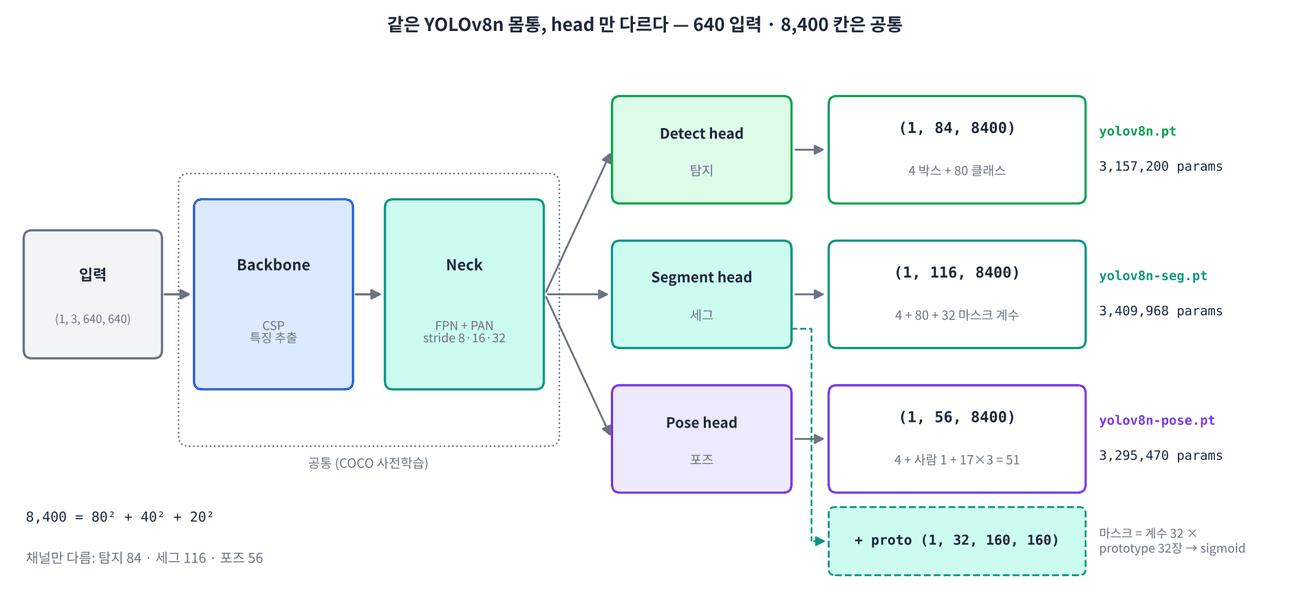

In [ ]:
#@title 🖼 그림 — 같은 몸통, 다른 head — 태스크별 출력 텐서
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f5_task_heads.png", embed=True, width=860))

**문제 4-1** 세 모델의 원시 출력 모양을 확인하고, 칸마다 숫자 개수를 계산하는 `n_channels` 와 맞춰 보세요.

In [ ]:
def n_channels(task, nc=80, nm=32, nk=17):
    if task == "detect": return 4 + nc
    if task == "segment": return 4 + nc + ____
    if task == "pose": return 4 + 1 + nk * ____

x640 = torch.zeros(1, 3, 640, 640)
raw_shapes = {}
for task, w in [("detect", "yolov8n.pt"), ("segment", "yolov8n-seg.pt"), ("pose", "yolov8n-pose.pt")]:
    with torch.no_grad():
        o = YOLO(w).model.eval()(x640)[0]
    o = o[0] if isinstance(o, (list, tuple)) else o                   # seg 는 (출력, prototype)
    raw_shapes[task] = tuple(o.shape)
    print(f"{task:8s} 원시 출력 {raw_shapes[task]} | 공식 {n_channels(task)}")

In [ ]:
assert all(raw_shapes[t] == (1, n_channels(t), 8400) for t in raw_shapes) and n_channels("pose") == 56; print("✅")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmRlZiBuX2NoYW5uZWxzKHRhc2ssIG5jPTgwLCBubT0zMiwgbms9MTcp"
    "OgogICAgaWYgdGFzayA9PSAiZGV0ZWN0IjogcmV0dXJuIDQgKyBuYwogICAgaWYgdGFzayA9PSAic2VnbWVudCI6"
    "IHJldHVybiA0ICsgbmMgKyBubQogICAgaWYgdGFzayA9PSAicG9zZSI6IHJldHVybiA0ICsgMSArIG5rICogMwoK"
    "eDY0MCA9IHRvcmNoLnplcm9zKDEsIDMsIDY0MCwgNjQwKQpyYXdfc2hhcGVzID0ge30KZm9yIHRhc2ssIHcgaW4g"
    "WygiZGV0ZWN0IiwgInlvbG92OG4ucHQiKSwgKCJzZWdtZW50IiwgInlvbG92OG4tc2VnLnB0IiksICgicG9zZSIs"
    "ICJ5b2xvdjhuLXBvc2UucHQiKV06CiAgICB3aXRoIHRvcmNoLm5vX2dyYWQoKToKICAgICAgICBvID0gWU9MTyh3"
    "KS5tb2RlbC5ldmFsKCkoeDY0MClbMF0KICAgIG8gPSBvWzBdIGlmIGlzaW5zdGFuY2UobywgKGxpc3QsIHR1cGxl"
    "KSkgZWxzZSBvICAgICAgICAgICAgICAgICAgICMgc2VnIOuKlCAo7Lac66ClLCBwcm90b3R5cGUpCiAgICByYXdf"
    "c2hhcGVzW3Rhc2tdID0gdHVwbGUoby5zaGFwZSkKICAgIHByaW50KGYie3Rhc2s6OHN9IOybkOyLnCDstpzroKUg"
    "e3Jhd19zaGFwZXNbdGFza119IHwg6rO17IudIHtuX2NoYW5uZWxzKHRhc2spfSIpCgrwn5KhIO2VtOyEpArshLjq"
    "t7ggaGVhZCDripQg66eI7Iqk7YGsICfqt7jrprwnIOuMgOyLoCDqs4TsiJggMzLqsJzrp4wg64K07IScIOy2nOug"
    "peydtCDsnpHqs6AsIHByb3RvdHlwZSDqs7wg7ISe7Ja0IOuniOyKpO2BrOulvCDrp4zrk63ri4jri6QuIO2PrOym"
    "iOuKlCDtgbTrnpjsiqTqsIAg7IKs656MIO2VmOuCmOudvCDsoJDsiJjqsIAgMeqwnCwg6rSA7KCI66eI64ukICh4"
    "LCB5LCBjb25mKSAz6rCcIOKGkiA0ICsgMSArIDUxID0gNTYuICoq6rCZ7J2AIOuquO2GteydtOuvgOuhnCDsho3r"
    "j4Trj4Qg6rGw7J2YIOqwmeyKteuLiOuLpCoqIOKAlCDtg5zsiqTtgazrpbwg67CU6r6464qUIOu5hOyaqeydtCDs"
    "npHsirXri4jri6Qu"
).decode("utf-8"))

**문제 4-2** 현장 시나리오에 맞는 태스크를 고르세요. `"cls"` (분류) · `"det"` (탐지) · `"seg"` (세그멘테이션) · `"pose"` (포즈) · `"det+roi"` (탐지 + 위험구역 판정) 중 하나.

In [ ]:
scenario = {
    "제품 사진 한 장의 양품 / 불량 판정": "cls",
    "작업장 출입 인원 세기": "det",
    "지게차와 사람 사이 거리 경고": ____,
    "바닥 기름 유출 영역의 넓이 재기": ____,
    "작업자 쓰러짐 감지": ____,
    "크레인 아래 위험구역에 발을 들였나": ____,
}
for k, v in scenario.items(): print(f"{v:8s} ← {k}")

In [ ]:
import hashlib
assert hashlib.md5("|".join(scenario.values()).encode()).hexdigest() == hashlib.md5("cls|det|det|seg|pose|det+roi".encode()).hexdigest(); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACnNjZW5hcmlvID0gewogICAgIuygnO2SiCDsgqzsp4Qg7ZWcIOyepeyd"
    "mCDslpHtkoggLyDrtojrn4kg7YyQ7KCVIjogImNscyIsCiAgICAi7J6R7JeF7J6lIOy2nOyehSDsnbjsm5Ag7IS4"
    "6riwIjogImRldCIsCiAgICAi7KeA6rKM7LCo7JmAIOyCrOuejCDsgqzsnbQg6rGw66asIOqyveqzoCI6ICJkZXQi"
    "LAogICAgIuuwlOuLpSDquLDrpoQg7Jyg7LacIOyYgeyXreydmCDrhJPsnbQg7J6s6riwIjogInNlZyIsCiAgICAi"
    "7J6R7JeF7J6QIOyTsOufrOynkCDqsJDsp4AiOiAicG9zZSIsCiAgICAi7YGs66CI7J24IOyVhOuemCDsnITtl5jq"
    "tazsl63sl5Ag67Cc7J2EIOuTpOyYgOuCmCI6ICJkZXQrcm9pIiwKfQpmb3IgaywgdiBpbiBzY2VuYXJpby5pdGVt"
    "cygpOiBwcmludChmInt2OjhzfSDihpAge2t9IikKCvCfkqEg7ZW07ISkCuqzoOultOuKlCDsiJzshJw6ICgxKSDt"
    "lYTsmpTtlZwg7Lac66Cl7J20IOustOyXh+yduOqwgCDigJQg7J6I64KYIC8g7Ja065SUIMK3IOuqhyDqsJwgLyDs"
    "lrTrlqQg66qo7JaRIMK3IOuEk+ydtCAvIOyWtOuWpCDsnpDshLguICgyKSDqt7jqsoPsnYQg7KO864qUICoq6rCA"
    "7J6lIOuLqOyInO2VnCoqIO2DnOyKpO2BrC4gKDMpIOyepey5mOyXkOyEnCDsho3rj4QuIOqxsOumrCDqsr3qs6Dr"
    "ipQg67CV7Iqk7J2YIOychOy5mCDCtyDtgazquLDroZwg7Lap67aE7ZWY6rOgIChkZXQpLCDsnITtl5jqtazsl63s"
    "nYAg67CcIOychOy5mOunjCDrs7TrqbQg65CY66+A66GcIO2DkOyngCArIFJPSSDroZwg6rCA67ON6rKMIO2SieuL"
    "iOuLpCDigJQgN+q1kOyLnCDtlITroZzsoJ3tirgu"
).decode("utf-8"))

#### 📌 4교시 정리

- 탐지 84 · 세그 116 (+prototype) · 포즈 56 — 같은 몸통, 다른 head.
- 태스크는 '필요한 출력' 으로 고르고, 가장 단순한 것부터.

## 5교시 — ONNX export · ONNX Runtime

**ONNX** (Open Neural Network Exchange) 는 프레임워크에 묶이지 않은 모델 파일 형식입니다 — **계산 그래프 + 가중치**. PyTorch 에서 내보내면 ONNX Runtime (CPU · 여러 장치), **TensorRT (Jetson, 내일부터)**, OpenVINO 등에서 그대로 읽습니다.

`torch.onnx.export` 는 예시 입력으로 모델을 한 번 실행하면서 연산을 기록 (**tracing**) 합니다.

| 인자 | 뜻 |
|---|---|
| 예시 입력 | 모양을 정해 주는 텐서 (1, 3, 224, 224) |
| `input_names` · `output_names` | 그래프 입출력 이름 (ONNX Runtime 에서 이 이름으로 넣고 뺌) |
| `dynamic_axes` | 바뀔 수 있는 축 — 배치 크기를 자유롭게 |
| `opset_version` | ONNX 연산자 버전 (17) — 받는 쪽이 지원하는 버전이어야 함 |

> 🎬 **애니메이션** [D5-5 ONNX 그래프](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

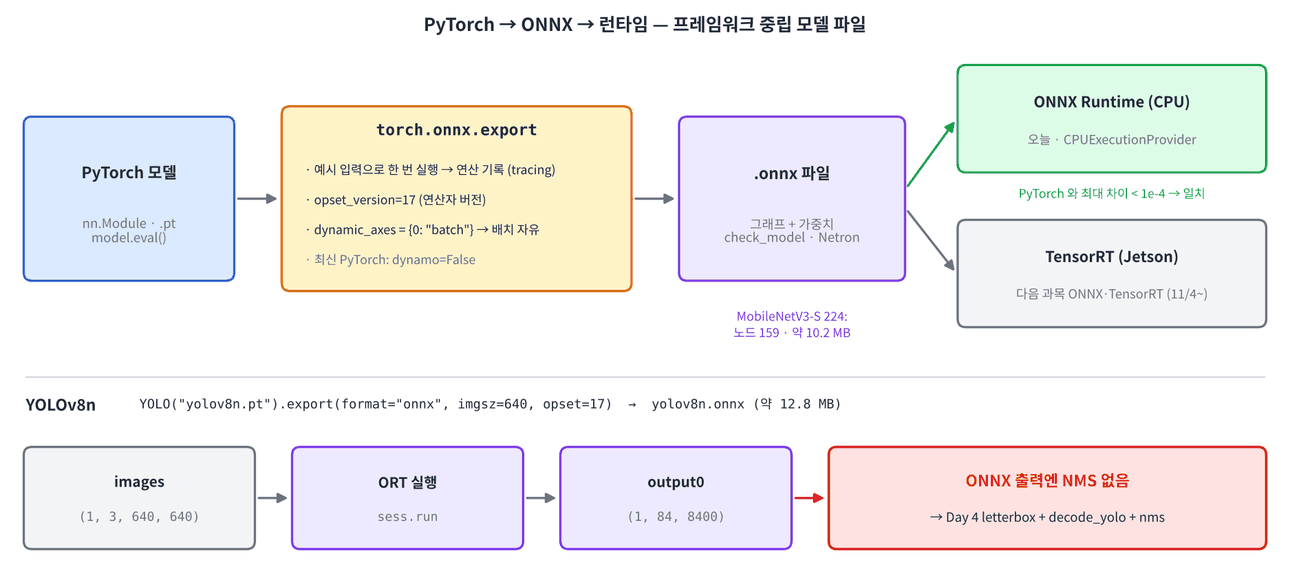

In [ ]:
#@title 🖼 그림 — PyTorch → ONNX → ONNX Runtime / TensorRT
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f6_onnx_flow.png", embed=True, width=860))

**문제 5-1** Day 3 의 MobileNetV3-Small (ImageNet 사전학습) 을 ONNX 로 내보내는 `export_onnx` 를 완성하세요. 배치 축을 dynamic 으로, opset 17. 최신 PyTorch 는 새 exporter (dynamo) 가 기본이라 기존 방식 (`dynamo=False`) 을 지정합니다.

In [ ]:
import onnx

def export_onnx(model, path, input_size=(1, 3, 224, 224)):
    model = copy.deepcopy(model).cpu().eval()
    kw = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
    torch.onnx.export(model, torch.randn(input_size), path, input_names=["input"], output_names=["logits"],
                      dynamic_axes={"input": {0: ____}, "logits": {0: "batch"}}, opset_version=____, **kw)
    m = onnx.load(path); onnx.checker.check_model(m)
    return m

mnv3 = torchvision.models.mobilenet_v3_small(weights="DEFAULT").eval()
onnx_mnv3 = export_onnx(mnv3, "mnv3s.onnx")
ops = sorted({n.op_type for n in onnx_mnv3.graph.node})
size_mb = os.path.getsize("mnv3s.onnx") / 1e6
n_params = sum(p.numel() for p in mnv3.parameters())
print(f"노드 {len(onnx_mnv3.graph.node)}개 | 연산 {ops}\n파일 {size_mb:.1f} MB | 파라미터 {n_params:,} × 4 B = {n_params * 4 / 1e6:.1f} MB")
print("입력", onnx_mnv3.graph.input[0].type.tensor_type.shape.dim[0].dim_param, "× 3 × 224 × 224")

In [ ]:
assert len(onnx_mnv3.graph.node) == 159 and "HardSwish" in ops and abs(size_mb - n_params * 4 / 1e6) < 0.3
assert onnx_mnv3.graph.input[0].type.tensor_type.shape.dim[0].dim_param == "batch"; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACmltcG9ydCBvbm54CgpkZWYgZXhwb3J0X29ubngobW9kZWwsIHBhdGgs"
    "IGlucHV0X3NpemU9KDEsIDMsIDIyNCwgMjI0KSk6CiAgICBtb2RlbCA9IGNvcHkuZGVlcGNvcHkobW9kZWwpLmNw"
    "dSgpLmV2YWwoKQogICAga3cgPSB7ImR5bmFtbyI6IEZhbHNlfSBpZiAiZHluYW1vIiBpbiBpbnNwZWN0LnNpZ25h"
    "dHVyZSh0b3JjaC5vbm54LmV4cG9ydCkucGFyYW1ldGVycyBlbHNlIHt9CiAgICB0b3JjaC5vbm54LmV4cG9ydCht"
    "b2RlbCwgdG9yY2gucmFuZG4oaW5wdXRfc2l6ZSksIHBhdGgsIGlucHV0X25hbWVzPVsiaW5wdXQiXSwgb3V0cHV0"
    "X25hbWVzPVsibG9naXRzIl0sCiAgICAgICAgICAgICAgICAgICAgICBkeW5hbWljX2F4ZXM9eyJpbnB1dCI6IHsw"
    "OiAiYmF0Y2gifSwgImxvZ2l0cyI6IHswOiAiYmF0Y2gifX0sIG9wc2V0X3ZlcnNpb249MTcsICoqa3cpCiAgICBt"
    "ID0gb25ueC5sb2FkKHBhdGgpOyBvbm54LmNoZWNrZXIuY2hlY2tfbW9kZWwobSkKICAgIHJldHVybiBtCgptbnYz"
    "ID0gdG9yY2h2aXNpb24ubW9kZWxzLm1vYmlsZW5ldF92M19zbWFsbCh3ZWlnaHRzPSJERUZBVUxUIikuZXZhbCgp"
    "Cm9ubnhfbW52MyA9IGV4cG9ydF9vbm54KG1udjMsICJtbnYzcy5vbm54IikKb3BzID0gc29ydGVkKHtuLm9wX3R5"
    "cGUgZm9yIG4gaW4gb25ueF9tbnYzLmdyYXBoLm5vZGV9KQpzaXplX21iID0gb3MucGF0aC5nZXRzaXplKCJtbnYz"
    "cy5vbm54IikgLyAxZTYKbl9wYXJhbXMgPSBzdW0ocC5udW1lbCgpIGZvciBwIGluIG1udjMucGFyYW1ldGVycygp"
    "KQpwcmludChmIuuFuOuTnCB7bGVuKG9ubnhfbW52My5ncmFwaC5ub2RlKX3qsJwgfCDsl7DsgrAge29wc31cbu2M"
    "jOydvCB7c2l6ZV9tYjouMWZ9IE1CIHwg7YyM652866+47YSwIHtuX3BhcmFtczosfSDDlyA0IEIgPSB7bl9wYXJh"
    "bXMgKiA0IC8gMWU2Oi4xZn0gTUIiKQpwcmludCgi7J6F66ClIiwgb25ueF9tbnYzLmdyYXBoLmlucHV0WzBdLnR5"
    "cGUudGVuc29yX3R5cGUuc2hhcGUuZGltWzBdLmRpbV9wYXJhbSwgIsOXIDMgw5cgMjI0IMOXIDIyNCIpCgrwn5Kh"
    "IO2VtOyEpArrhbjrk5wgMTU56rCcIOKAlCBDb252IMK3IEhhcmRTd2lzaCDCtyBIYXJkU2lnbW9pZCAoU0UpIMK3"
    "IEdsb2JhbEF2ZXJhZ2VQb29sIMK3IEdlbW0g65OxIERheSAzIOyXkOyEnCDrs7gg67aA7ZKIIOq3uOuMgOuhnOye"
    "heuLiOuLpC4g7YyM7J28IO2BrOq4sCDiiYgg7YyM652866+47YSwIMOXIDQgQiAoZmxvYXQzMikgKyDqt7jrnpjt"
    "lIQg7KCV67O0LiDsmbzsqr0g7YyM7J28IO2DreyXkOyEnCBgbW52M3Mub25ueGAg66W8IOuCtOugpOuwm+yVhCAq"
    "Km5ldHJvbi5hcHAqKiDsl5Ag64GM7Ja064ukIOuGk+ycvOuptCDqt7jrnpjtlITrpbwg67O8IOyImCDsnojsirXr"
    "i4jri6QuIEJhdGNoTm9ybSDsnYAgdHJhY2luZyDtlaAg65WMIENvbnYg7JeQIO2VqeyzkOyguCAoZm9sZCkg65Sw"
    "66GcIOuFuOuTnOqwgCDsl4bsirXri4jri6Qu"
).decode("utf-8"))

**문제 5-2** ONNX Runtime 으로 실행해 PyTorch 결과와 같은지 확인하세요. dynamic axes 덕분에 배치 4 도 들어가야 합니다.

In [ ]:
import onnxruntime as ort
sess_mnv3 = ort.InferenceSession("mnv3s.onnx", providers=[____])
xb = torch.randn(4, 3, 224, 224)
with torch.no_grad():
    ref = mnv3(xb).numpy()
onx = sess_mnv3.run(None, {____: xb.numpy()})[0]
diff_mnv3 = float(np.abs(onx - ref).max())
print("입력", [(i.name, i.shape) for i in sess_mnv3.get_inputs()], "| 출력", onx.shape, f"| 최대 차이 {diff_mnv3:.2e}")

In [ ]:
assert onx.shape == (4, 1000) and diff_mnv3 < 1e-4; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmltcG9ydCBvbm54cnVudGltZSBhcyBvcnQKc2Vzc19tbnYzID0gb3J0"
    "LkluZmVyZW5jZVNlc3Npb24oIm1udjNzLm9ubngiLCBwcm92aWRlcnM9WyJDUFVFeGVjdXRpb25Qcm92aWRlciJd"
    "KQp4YiA9IHRvcmNoLnJhbmRuKDQsIDMsIDIyNCwgMjI0KQp3aXRoIHRvcmNoLm5vX2dyYWQoKToKICAgIHJlZiA9"
    "IG1udjMoeGIpLm51bXB5KCkKb254ID0gc2Vzc19tbnYzLnJ1bihOb25lLCB7ImlucHV0IjogeGIubnVtcHkoKX0p"
    "WzBdCmRpZmZfbW52MyA9IGZsb2F0KG5wLmFicyhvbnggLSByZWYpLm1heCgpKQpwcmludCgi7J6F66ClIiwgWyhp"
    "Lm5hbWUsIGkuc2hhcGUpIGZvciBpIGluIHNlc3NfbW52My5nZXRfaW5wdXRzKCldLCAifCDstpzroKUiLCBvbngu"
    "c2hhcGUsIGYifCDstZzrjIAg7LCo7J20IHtkaWZmX21udjM6LjJlfSIpCgrwn5KhIO2VtOyEpArssKjsnbTqsIAg"
    "MWUtNSDsiJjspIDsnbTrqbQgJ+qwmeydgCDrqqjrjbgnIOyeheuLiOuLpCAo7Jew7IKwIOyInOyEnCDCtyDstZzs"
    "oIHtmZQg7LCo7J2066GcIOyDneq4sOuKlCDrtoDrj5nshozsiJgg7Jik7LCoKS4g67OA7ZmYIO2bhOyXkOuKlCAq"
    "Ku2VreyDgSDsnbQg6rKA7KadKirsnYQg7ZWp64uI64ukIOKAlCBUZW5zb3JSVCDCtyBpbnQ4IOyWkeyekO2ZlCDt"
    "m4Tsl5Drj4Qg6rCZ7J2AIOuwqeyLneycvOuhnCAn7Ja866eI64KYIOuLrOudvOyhjOuCmCcg66W8IOu0heuLiOuL"
    "pC4="
).decode("utf-8"))

**문제 5-3** YOLOv8n 을 ONNX 로 내보내고 (ultralytics `export`), ONNX Runtime 출력 (1, 84, 8400) 을 **Day 4 의 `decode_yolo`** 로 후처리하세요. ONNX 출력에는 NMS 가 없습니다. PyTorch 결과와 같은 박스가 나와야 합니다.

In [ ]:
yolo = YOLO("yolov8n.pt")
onnx_path = yolo.export(format=____, imgsz=640, opset=17, verbose=False)
sess_yolo = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
print([(i.name, i.shape) for i in sess_yolo.get_inputs()], [(o.name, o.shape) for o in sess_yolo.get_outputs()])

lb, ratio, (padl, padt) = letterbox(frame200)
x = (lb[..., ::-1].transpose(2, 0, 1)[None] / 255.0).astype(np.float32)          # BGR→RGB, CHW, 0~1
raw_onnx = sess_yolo.run(None, {____: x})[0]
ob, oc = decode_yolo(raw_onnx)
ref = YOLO("yolov8n.pt").predict(lb, imgsz=640, conf=0.25, iou=0.7, classes=[0], verbose=False)[0]
rb = ref.boxes.xyxy.cpu().numpy()
print(f"ONNX {len(ob)}명 · PyTorch {len(rb)}명 | 짝 IoU 최소 {iou_matrix(ob, rb).max(1).min():.4f}")
show([draw_boxes(frame200[..., ::-1], (ob - [padl, padt, padl, padt]) / ratio, (255, 60, 60))], ["ONNX Runtime + decode_yolo"], cols=1, size=5)

In [ ]:
assert raw_onnx.shape == (1, 84, 8400) and len(ob) == len(rb) > 0 and iou_matrix(ob, rb).max(1).min() > 0.99; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACnlvbG8gPSBZT0xPKCJ5b2xvdjhuLnB0IikKb25ueF9wYXRoID0geW9s"
    "by5leHBvcnQoZm9ybWF0PSJvbm54IiwgaW1nc3o9NjQwLCBvcHNldD0xNywgdmVyYm9zZT1GYWxzZSkKc2Vzc195"
    "b2xvID0gb3J0LkluZmVyZW5jZVNlc3Npb24ob25ueF9wYXRoLCBwcm92aWRlcnM9WyJDUFVFeGVjdXRpb25Qcm92"
    "aWRlciJdKQpwcmludChbKGkubmFtZSwgaS5zaGFwZSkgZm9yIGkgaW4gc2Vzc195b2xvLmdldF9pbnB1dHMoKV0s"
    "IFsoby5uYW1lLCBvLnNoYXBlKSBmb3IgbyBpbiBzZXNzX3lvbG8uZ2V0X291dHB1dHMoKV0pCgpsYiwgcmF0aW8s"
    "IChwYWRsLCBwYWR0KSA9IGxldHRlcmJveChmcmFtZTIwMCkKeCA9IChsYlsuLi4sIDo6LTFdLnRyYW5zcG9zZSgy"
    "LCAwLCAxKVtOb25lXSAvIDI1NS4wKS5hc3R5cGUobnAuZmxvYXQzMikgICAgICAgICAgIyBCR1LihpJSR0IsIENI"
    "VywgMH4xCnJhd19vbm54ID0gc2Vzc195b2xvLnJ1bihOb25lLCB7ImltYWdlcyI6IHh9KVswXQpvYiwgb2MgPSBk"
    "ZWNvZGVfeW9sbyhyYXdfb25ueCkKcmVmID0gWU9MTygieW9sb3Y4bi5wdCIpLnByZWRpY3QobGIsIGltZ3N6PTY0"
    "MCwgY29uZj0wLjI1LCBpb3U9MC43LCBjbGFzc2VzPVswXSwgdmVyYm9zZT1GYWxzZSlbMF0KcmIgPSByZWYuYm94"
    "ZXMueHl4eS5jcHUoKS5udW1weSgpCnByaW50KGYiT05OWCB7bGVuKG9iKX3rqoUgwrcgUHlUb3JjaCB7bGVuKHJi"
    "KX3rqoUgfCDsp50gSW9VIOy1nOyGjCB7aW91X21hdHJpeChvYiwgcmIpLm1heCgxKS5taW4oKTouNGZ9IikKc2hv"
    "dyhbZHJhd19ib3hlcyhmcmFtZTIwMFsuLi4sIDo6LTFdLCAob2IgLSBbcGFkbCwgcGFkdCwgcGFkbCwgcGFkdF0p"
    "IC8gcmF0aW8sICgyNTUsIDYwLCA2MCkpXSwgWyJPTk5YIFJ1bnRpbWUgKyBkZWNvZGVfeW9sbyJdLCBjb2xzPTEs"
    "IHNpemU9NSkKCvCfkqEg7ZW07ISkCk9OTlgg7YyM7J28IO2VmOuCmCArIE51bVB5IO2bhOyymOumrCAobGV0dGVy"
    "Ym94IMK3IGRlY29kZSDCtyBubXMpIOunjCDsnojsnLzrqbQgUHlUb3JjaCDCtyB1bHRyYWx5dGljcyDsl4bsnbTr"
    "j4Qg7YOQ7KeA6riw6rCAIOuPjOyVhOqwkeuLiOuLpC4gSmV0c29uIMK3IOudvOymiOuyoOumrO2MjOydtOyXkCDs"
    "mKzrprQg65WMIOydtCDqtazshLHsnYQg6re464yA66GcIOyUgeuLiOuLpC4gN+q1kOyLnCDtlITroZzsoJ3tirjs"
    "nZgg7YOQ7KeA6riw6rCAIOuwlOuhnCDsnbTqsoPsnoXri4jri6Qu"
).decode("utf-8"))

#### 📌 5교시 정리

- torch.onnx.export = tracing. input/output 이름 · dynamic axes · opset.
- 변환 후 반드시 ONNX Runtime 출력과 PyTorch 출력 비교 (최대 차이).
- YOLO ONNX 는 원시 출력만 → letterbox + decode_yolo + nms 를 직접.

## 6교시 — 성능 측정법: baseline 성능표

Day 3 의 `latency_ms` 를 보고서용으로 키웁니다.

| 항목 | 이유 |
|---|---|
| **warm-up** (5회 버림) | 첫 실행은 메모리 할당 · 캐시 · 최적화 때문에 느리다 |
| **평균 · p50 · p95** | 지연시간은 가끔 크게 튄다 (꼬리). p95 = 100번 중 95번은 이보다 빠름 — 실시간 시스템은 p95 로 판단 |
| **FPS** = 1000 / 평균 ms | 초당 처리 프레임 |
| **스레드 1 · 2 · 전체** | 작은 장치의 코어 수 흉내. 늘려도 그만큼 빨라지지는 않는다 |
| **파일 크기 (MB)** | 장치 저장 공간 · 로딩 시간 |

**같은 조건**에서 PyTorch 와 ONNX Runtime 을 비교합니다 (CPU, 배치 1, 전 · 후처리 제외한 모델 실행만).

> 🎬 **애니메이션** [D5-6 latency 분포와 스레드](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

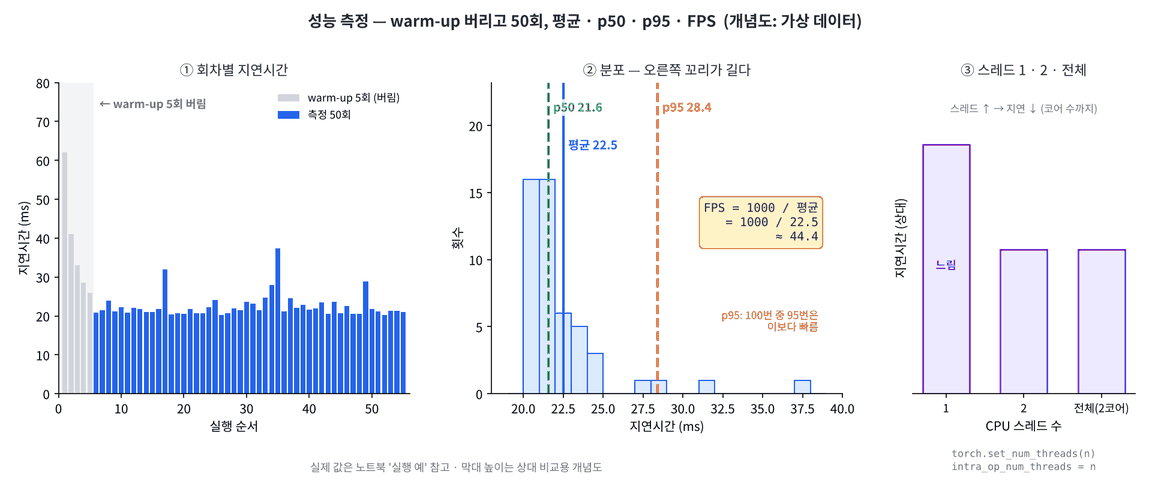

In [ ]:
#@title 🖼 그림 — 지연시간 분포 · warm-up · p95
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f7_latency.png", embed=True, width=780))

**문제 6-1** 함수 `fn` 을 warm-up 후 여러 번 실행해 평균 · p50 · p95 · FPS 를 돌려주는 `benchmark` 를 완성하세요.

In [ ]:
def benchmark(fn, warmup=5, reps=50):
    for _ in range(____):
        fn()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append((time.perf_counter() - t0) * 1000)
    ts = np.array(ts)
    return {"mean": float(ts.mean()), "p50": float(np.percentile(ts, 50)),
            "p95": float(np.percentile(ts, ____)), "fps": float(1000 / ____)}

print(benchmark(lambda: time.sleep(0.01), warmup=1, reps=20))

In [ ]:
b_ = benchmark(lambda: time.sleep(0.005), warmup=1, reps=10)
assert set(b_) == {"mean", "p50", "p95", "fps"} and 5 <= b_["mean"] < 50 and b_["p95"] >= b_["p50"] and np.isclose(b_["fps"], 1000 / b_["mean"]); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmRlZiBiZW5jaG1hcmsoZm4sIHdhcm11cD01LCByZXBzPTUwKToKICAg"
    "IGZvciBfIGluIHJhbmdlKHdhcm11cCk6CiAgICAgICAgZm4oKQogICAgdHMgPSBbXQogICAgZm9yIF8gaW4gcmFu"
    "Z2UocmVwcyk6CiAgICAgICAgdDAgPSB0aW1lLnBlcmZfY291bnRlcigpOyBmbigpOyB0cy5hcHBlbmQoKHRpbWUu"
    "cGVyZl9jb3VudGVyKCkgLSB0MCkgKiAxMDAwKQogICAgdHMgPSBucC5hcnJheSh0cykKICAgIHJldHVybiB7Im1l"
    "YW4iOiBmbG9hdCh0cy5tZWFuKCkpLCAicDUwIjogZmxvYXQobnAucGVyY2VudGlsZSh0cywgNTApKSwKICAgICAg"
    "ICAgICAgInA5NSI6IGZsb2F0KG5wLnBlcmNlbnRpbGUodHMsIDk1KSksICJmcHMiOiBmbG9hdCgxMDAwIC8gdHMu"
    "bWVhbigpKX0KCnByaW50KGJlbmNobWFyayhsYW1iZGE6IHRpbWUuc2xlZXAoMC4wMSksIHdhcm11cD0xLCByZXBz"
    "PTIwKSk="
).decode("utf-8"))

**문제 6-2** MobileNetV3-Small (224) 과 YOLOv8n (640) 을 **PyTorch vs ONNX Runtime**, **스레드 1 · 2 · 전체** 로 재세요. ONNX Runtime 스레드 수는 `SessionOptions().intra_op_num_threads` 로 정합니다. (약 2~3분)

In [ ]:
THREADS = sorted({1, 2, os.cpu_count()})
yolo_torch = YOLO("yolov8n.pt").model.eval().cpu()
x224, x640n = torch.randn(1, 3, 224, 224), torch.zeros(1, 3, 640, 640)

def ort_session(path, n):
    so = ort.SessionOptions(); so.intra_op_num_threads = ____
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])

rows = []
old = torch.get_num_threads()
for n in THREADS:
    torch.set_num_threads(____)
    s_m, s_y = ort_session("mnv3s.onnx", n), ort_session(onnx_path, n)
    with torch.no_grad():
        cases = [("MobileNetV3-S", "PyTorch", 224, lambda: mnv3(x224)),
                 ("MobileNetV3-S", "ONNX Runtime", 224, lambda: s_m.run(None, {"input": x224.numpy()})),
                 ("YOLOv8n", "PyTorch", 640, lambda: yolo_torch(x640n)),
                 ("YOLOv8n", "ONNX Runtime", 640, lambda: s_y.run(None, {"images": x640n.numpy()}))]
        for model_name, fw, sz, fn in cases:
            b = benchmark(fn, warmup=5, reps=30 if model_name == "YOLOv8n" else 50)
            rows.append({"model": model_name, "framework": fw, "input": sz, "threads": n, **b})
            print(f"{model_name:14s} {fw:13s} 스레드 {n} | 평균 {b['mean']:7.1f} ms · p95 {b['p95']:7.1f} · {b['fps']:6.1f} FPS")
torch.set_num_threads(old)

In [ ]:
assert len(rows) == 4 * len(THREADS) and all(r_["mean"] > 0 and r_["p95"] >= r_["p50"] for r_ in rows); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSAClRIUkVBRFMgPSBzb3J0ZWQoezEsIDIsIG9zLmNwdV9jb3VudCgpfSkK"
    "eW9sb190b3JjaCA9IFlPTE8oInlvbG92OG4ucHQiKS5tb2RlbC5ldmFsKCkuY3B1KCkKeDIyNCwgeDY0MG4gPSB0"
    "b3JjaC5yYW5kbigxLCAzLCAyMjQsIDIyNCksIHRvcmNoLnplcm9zKDEsIDMsIDY0MCwgNjQwKQoKZGVmIG9ydF9z"
    "ZXNzaW9uKHBhdGgsIG4pOgogICAgc28gPSBvcnQuU2Vzc2lvbk9wdGlvbnMoKTsgc28uaW50cmFfb3BfbnVtX3Ro"
    "cmVhZHMgPSBuCiAgICByZXR1cm4gb3J0LkluZmVyZW5jZVNlc3Npb24ocGF0aCwgc28sIHByb3ZpZGVycz1bIkNQ"
    "VUV4ZWN1dGlvblByb3ZpZGVyIl0pCgpyb3dzID0gW10Kb2xkID0gdG9yY2guZ2V0X251bV90aHJlYWRzKCkKZm9y"
    "IG4gaW4gVEhSRUFEUzoKICAgIHRvcmNoLnNldF9udW1fdGhyZWFkcyhuKQogICAgc19tLCBzX3kgPSBvcnRfc2Vz"
    "c2lvbigibW52M3Mub25ueCIsIG4pLCBvcnRfc2Vzc2lvbihvbm54X3BhdGgsIG4pCiAgICB3aXRoIHRvcmNoLm5v"
    "X2dyYWQoKToKICAgICAgICBjYXNlcyA9IFsoIk1vYmlsZU5ldFYzLVMiLCAiUHlUb3JjaCIsIDIyNCwgbGFtYmRh"
    "OiBtbnYzKHgyMjQpKSwKICAgICAgICAgICAgICAgICAoIk1vYmlsZU5ldFYzLVMiLCAiT05OWCBSdW50aW1lIiwg"
    "MjI0LCBsYW1iZGE6IHNfbS5ydW4oTm9uZSwgeyJpbnB1dCI6IHgyMjQubnVtcHkoKX0pKSwKICAgICAgICAgICAg"
    "ICAgICAoIllPTE92OG4iLCAiUHlUb3JjaCIsIDY0MCwgbGFtYmRhOiB5b2xvX3RvcmNoKHg2NDBuKSksCiAgICAg"
    "ICAgICAgICAgICAgKCJZT0xPdjhuIiwgIk9OTlggUnVudGltZSIsIDY0MCwgbGFtYmRhOiBzX3kucnVuKE5vbmUs"
    "IHsiaW1hZ2VzIjogeDY0MG4ubnVtcHkoKX0pKV0KICAgICAgICBmb3IgbW9kZWxfbmFtZSwgZncsIHN6LCBmbiBp"
    "biBjYXNlczoKICAgICAgICAgICAgYiA9IGJlbmNobWFyayhmbiwgd2FybXVwPTUsIHJlcHM9MzAgaWYgbW9kZWxf"
    "bmFtZSA9PSAiWU9MT3Y4biIgZWxzZSA1MCkKICAgICAgICAgICAgcm93cy5hcHBlbmQoeyJtb2RlbCI6IG1vZGVs"
    "X25hbWUsICJmcmFtZXdvcmsiOiBmdywgImlucHV0Ijogc3osICJ0aHJlYWRzIjogbiwgKipifSkKICAgICAgICAg"
    "ICAgcHJpbnQoZiJ7bW9kZWxfbmFtZToxNHN9IHtmdzoxM3N9IOyKpOugiOuTnCB7bn0gfCDtj4nqt6Age2JbJ21l"
    "YW4nXTo3LjFmfSBtcyDCtyBwOTUge2JbJ3A5NSddOjcuMWZ9IMK3IHtiWydmcHMnXTo2LjFmfSBGUFMiKQp0b3Jj"
    "aC5zZXRfbnVtX3RocmVhZHMob2xkKQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiCAoQ1BVLCDsiqTroIjrk5wgMSk6"
    "IE1vYmlsZU5ldFYzLVMgUHlUb3JjaCAxMS4wIG1zIHZzIE9OTlggUnVudGltZSA0LjYgbXMgwrcgWU9MT3Y4biBQ"
    "eVRvcmNoIDIxOS41IG1zIHZzIE9OTlggUnVudGltZSAxNTkuNCBtcy4gT05OWCBSdW50aW1lIOydgCDqt7jrnpjt"
    "lIQg7KCE7LK066W8IOuztOqzoCDsl7DsgrDsnYQg7ZWp7LmY6rOgIChmdXNpb24pIOuplOuqqOumrOulvCDrr7jr"
    "pqwg7J6h7JWEIOuztO2GtSDrjZQg67mg66aF64uI64ukLiDsiqTroIjrk5zrpbwgMuuwsOuhnCDripjroKTrj4Qg"
    "MuuwsCDruajrnbzsp4Dsp4Ag7JWK7Iq164uI64ukIOKAlCDsnpHsnYAg66qo64247J287IiY66GdIOuCmOuIhOuK"
    "lCDruYTsmqnsnbQg7YG964uI64ukLg=="
).decode("utf-8"))

**문제 6-3** 파일 크기를 더해 **baseline 성능표**를 `baseline.csv` 로 저장하세요. 내일 ONNX·TensorRT 과목에서 Jetson 결과와 이 표를 나란히 놓습니다.

In [ ]:
torch.save(mnv3.state_dict(), "mnv3s.pt")
size_of = {("MobileNetV3-S", "PyTorch"): "mnv3s.pt", ("MobileNetV3-S", "ONNX Runtime"): "mnv3s.onnx",
           ("YOLOv8n", "PyTorch"): "yolov8n.pt", ("YOLOv8n", "ONNX Runtime"): ____}
for r_ in rows:
    r_["file_MB"] = round(os.path.getsize(size_of[(r_["model"], r_["framework"])]) / 1e6, 2)
cols = ["model", "framework", "input", "threads", "mean", "p50", "p95", "fps", "file_MB"]
with open("baseline.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader()
    for r_ in rows:
        w.writerow({k: (round(r_[k], 2) if isinstance(r_[k], float) else r_[k]) for k in ____})
print(open("baseline.csv").read())

In [ ]:
lines = open("baseline.csv").read().strip().splitlines()
assert lines[0] == "model,framework,input,threads,mean,p50,p95,fps,file_MB" and len(lines) == len(rows) + 1; print("✅")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACnRvcmNoLnNhdmUobW52My5zdGF0ZV9kaWN0KCksICJtbnYzcy5wdCIp"
    "CnNpemVfb2YgPSB7KCJNb2JpbGVOZXRWMy1TIiwgIlB5VG9yY2giKTogIm1udjNzLnB0IiwgKCJNb2JpbGVOZXRW"
    "My1TIiwgIk9OTlggUnVudGltZSIpOiAibW52M3Mub25ueCIsCiAgICAgICAgICAgKCJZT0xPdjhuIiwgIlB5VG9y"
    "Y2giKTogInlvbG92OG4ucHQiLCAoIllPTE92OG4iLCAiT05OWCBSdW50aW1lIik6IG9ubnhfcGF0aH0KZm9yIHJf"
    "IGluIHJvd3M6CiAgICByX1siZmlsZV9NQiJdID0gcm91bmQob3MucGF0aC5nZXRzaXplKHNpemVfb2ZbKHJfWyJt"
    "b2RlbCJdLCByX1siZnJhbWV3b3JrIl0pXSkgLyAxZTYsIDIpCmNvbHMgPSBbIm1vZGVsIiwgImZyYW1ld29yayIs"
    "ICJpbnB1dCIsICJ0aHJlYWRzIiwgIm1lYW4iLCAicDUwIiwgInA5NSIsICJmcHMiLCAiZmlsZV9NQiJdCndpdGgg"
    "b3BlbigiYmFzZWxpbmUuY3N2IiwgInciLCBuZXdsaW5lPSIiKSBhcyBmOgogICAgdyA9IGNzdi5EaWN0V3JpdGVy"
    "KGYsIGZpZWxkbmFtZXM9Y29scyk7IHcud3JpdGVoZWFkZXIoKQogICAgZm9yIHJfIGluIHJvd3M6CiAgICAgICAg"
    "dy53cml0ZXJvdyh7azogKHJvdW5kKHJfW2tdLCAyKSBpZiBpc2luc3RhbmNlKHJfW2tdLCBmbG9hdCkgZWxzZSBy"
    "X1trXSkgZm9yIGsgaW4gY29sc30pCnByaW50KG9wZW4oImJhc2VsaW5lLmNzdiIpLnJlYWQoKSkKCvCfkqEg7ZW0"
    "7ISkCnlvbG92OG4ucHQgKOyVvSA2LjUgTUIpIOqwgCB5b2xvdjhuLm9ubnggKOyVvSAxMi44IE1CKSDrs7Tri6Qg"
    "7J6R7J2AIOqyg+ydgCAucHQg6rCAIOqwgOykkey5mOulvCBmbG9hdDE2IOycvOuhnCDsoIDsnqXtlbQg65GQ6riw"
    "IOuVjOusuOyeheuLiOuLpC4gT05OWCDripQgZmxvYXQzMi4gMTEvMTZ+IFF1YW50aXphdGlvbiDqs7zrqqnsl5Ds"
    "hJwgaW50OCDroZwg67CU6r6466m0IDEvNCDroZwg7KSE7Ja065Ot64uI64ukLg=="
).decode("utf-8"))

#### 📌 6교시 정리

- warm-up 버리고 → 평균 · p50 · p95 · FPS. 실시간 판단은 p95.
- 같은 조건 (CPU · 배치 1 · 스레드 수) 에서 PyTorch vs ONNX Runtime. 스레드는 효과가 줄어든다.
- baseline.csv = 다음 과목의 비교 기준.

## 7교시 — 종합 미니 프로젝트: 위험구역 침입 감지

5일 동안 만든 것을 모읍니다 — 영상 파이프라인 (Day 1) · CNN 탐지기 (Day 2~4) · letterbox · decode · NMS (Day 4) · ONNX Runtime · 성능 측정 (Day 5).

```
people.mp4 → ONNX Runtime YOLOv8n → 사람 박스 → 발 위치 (박스 아래 중앙) → 위험구역 다각형 안? → 3 프레임 연속이면 경보
          → 결과 영상 (구역 · 박스 색 · 경보 문구) + CSV 로그 (frame, time_s, n_people, n_inside, alarm)
```

- **위험구역** = 영상 왼쪽 아래 **잔디 보호구역** — 다각형 `GRASS` (768×576 좌표)
- **발 위치** = 박스 아래 중앙 ((x1 + x2) / 2, y2) — 박스 전체나 중심 대신 '바닥에 닿은 점' 으로 판정 (1교시: 박스 안 절반은 배경)
- **debounce** — 한 프레임만 들어갔다 나오는 오탐 · 깜빡임을 막으려고 **3 프레임 연속** 구역 안 사람이 있을 때만 경보

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 구역 판정 `in_zone` · 발 위치 `foot_points` | 20 |
| 2 | ONNX 탐지 함수 `detect_onnx` | 20 |
| 3 | 영상 처리 · 3프레임 경보 · 결과 영상 · CSV 로그 | 20 |
| 4 | 이벤트 요약 + 성능 → baseline 표에 한 줄 추가 | 20 |
| 5 | 발표 · 해석 (8교시) | 20 (강사) |

강사 사전 실행 예 (CPU): 795 프레임 중 경보 224 프레임, 이벤트 5 번.

> 🎬 **애니메이션** [D5-7 ROI 다각형과 침입 판정](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

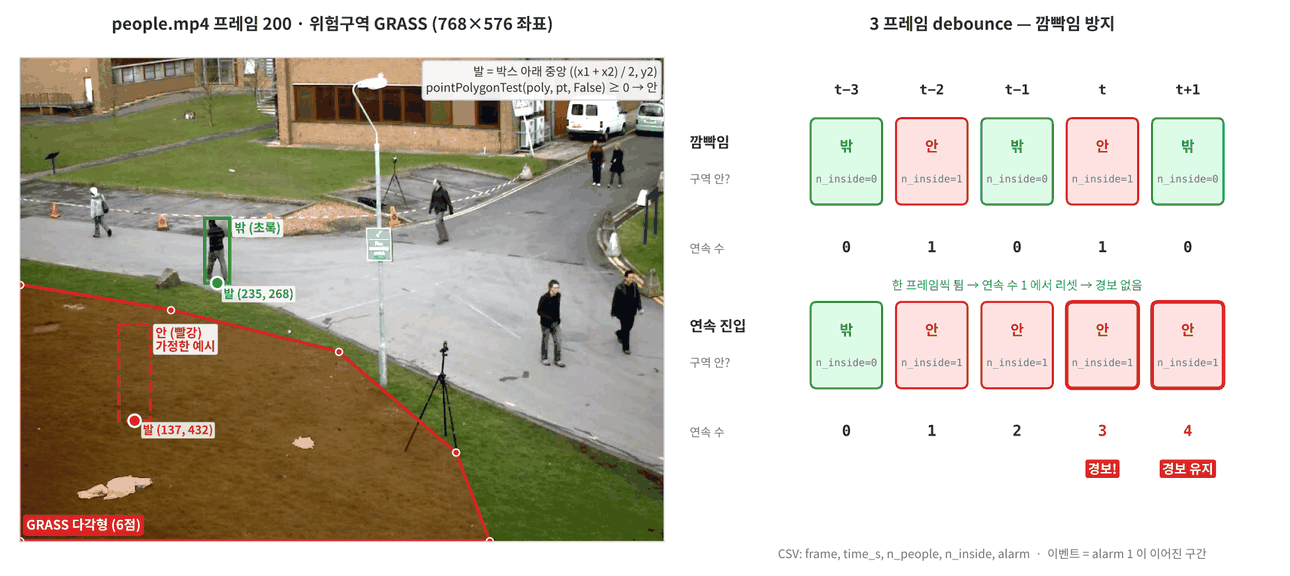

In [ ]:
#@title 🖼 그림 — 위험구역 다각형 · 발 위치 · 3 프레임 debounce
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day5/img/f8_intrusion.png", embed=True, width=860))

In [ ]:
GRASS = np.array([(0, 270), (180, 300), (380, 350), (520, 470), (560, 575), (0, 575)], np.int32)
vis = frame200.copy(); ov = vis.copy()
cv2.fillPoly(ov, [GRASS], (0, 0, 255)); vis = cv2.addWeighted(ov, 0.3, vis, 0.7, 0)
cv2.polylines(vis, [GRASS], True, (0, 0, 255), 2)
show([vis[..., ::-1]], ["danger zone (GRASS polygon)"], cols=1, size=5.5)

### 과제 1 — 구역 판정 · 발 위치 (20점)

`cv2.pointPolygonTest(다각형, (x, y), False)` 는 안 = +1, 선 위 = 0, 밖 = −1 을 돌려줍니다. 선 위도 '안' 으로 봅니다.

In [ ]:
def in_zone(pt, poly=GRASS):
    return cv2.pointPolygonTest(poly, (float(pt[0]), float(pt[1])), False) ____ 0

def foot_points(boxes):
    boxes = np.asarray(boxes, float).reshape(-1, 4)
    return np.stack([(boxes[:, 0] + boxes[:, 2]) / 2, ____], 1)

for pt in [(100, 400), (600, 200), (300, 340), (300, 320)]:
    print(pt, "안" if in_zone(pt) else "밖")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmRlZiBpbl96b25lKHB0LCBwb2x5PUdSQVNTKToKICAgIHJldHVybiBj"
    "djIucG9pbnRQb2x5Z29uVGVzdChwb2x5LCAoZmxvYXQocHRbMF0pLCBmbG9hdChwdFsxXSkpLCBGYWxzZSkgPj0g"
    "MAoKZGVmIGZvb3RfcG9pbnRzKGJveGVzKToKICAgIGJveGVzID0gbnAuYXNhcnJheShib3hlcywgZmxvYXQpLnJl"
    "c2hhcGUoLTEsIDQpCiAgICByZXR1cm4gbnAuc3RhY2soWyhib3hlc1s6LCAwXSArIGJveGVzWzosIDJdKSAvIDIs"
    "IGJveGVzWzosIDNdXSwgMSkKCvCfkqEg7ZW07ISkCigzMDAsIDM0MCkg7J2AIOyViCwgKDMwMCwgMzIwKSDsnYAg"
    "67CWIOKAlCDrs4AgKDE4MCwgMzAwKeKAkygzODAsIDM1MCkg7JyEIHggPSAzMDAg7KeA7KCQ7J2YIHkg64qUIDMz"
    "MCDsnoXri4jri6QuIHkg6rCAIOyVhOuemOuhnCDsu6Tsp4DripQg7KKM7ZGc6528ICfshKDrs7Tri6Qg7JWE656Y"
    "JyA9IHkg6rCAIOuNlCDtgbwu"
).decode("utf-8"))

### 과제 2 — ONNX 탐지 함수 (20점)

5교시의 `sess_yolo` 로 프레임 (BGR, 원본 크기) 에서 사람 박스를 **원본 좌표**로 돌려주는 `detect_onnx` 를 완성하세요 — letterbox → (1, 3, 640, 640) float32 → ONNX Runtime → `decode_yolo` → 패딩 빼고 ÷ r → 화면 밖은 자르기.

In [ ]:
def detect_onnx(frame, sess=sess_yolo, conf=0.25, iou_thr=0.7):
    lb, r, (pl, pt) = letterbox(frame)
    x = (lb[..., ::-1].transpose(2, 0, 1)[None] / 255.0).astype(np.float32)
    out = sess.run(None, {"images": ____})[0]
    boxes, scores = decode_yolo(out, conf, iou_thr)
    boxes = (boxes - [pl, pt, pl, pt]) / ____
    H, W = frame.shape[:2]
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, W); boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, ____)
    return boxes, scores

b200, s200 = detect_onnx(frame200)
print(len(b200), "명 | 발 위치", foot_points(b200).round(0)[:3], "...")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmRlZiBkZXRlY3Rfb25ueChmcmFtZSwgc2Vzcz1zZXNzX3lvbG8sIGNv"
    "bmY9MC4yNSwgaW91X3Rocj0wLjcpOgogICAgbGIsIHIsIChwbCwgcHQpID0gbGV0dGVyYm94KGZyYW1lKQogICAg"
    "eCA9IChsYlsuLi4sIDo6LTFdLnRyYW5zcG9zZSgyLCAwLCAxKVtOb25lXSAvIDI1NS4wKS5hc3R5cGUobnAuZmxv"
    "YXQzMikKICAgIG91dCA9IHNlc3MucnVuKE5vbmUsIHsiaW1hZ2VzIjogeH0pWzBdCiAgICBib3hlcywgc2NvcmVz"
    "ID0gZGVjb2RlX3lvbG8ob3V0LCBjb25mLCBpb3VfdGhyKQogICAgYm94ZXMgPSAoYm94ZXMgLSBbcGwsIHB0LCBw"
    "bCwgcHRdKSAvIHIKICAgIEgsIFcgPSBmcmFtZS5zaGFwZVs6Ml0KICAgIGJveGVzWzosIFswLCAyXV0gPSBib3hl"
    "c1s6LCBbMCwgMl1dLmNsaXAoMCwgVyk7IGJveGVzWzosIFsxLCAzXV0gPSBib3hlc1s6LCBbMSwgM11dLmNsaXAo"
    "MCwgSCkKICAgIHJldHVybiBib3hlcywgc2NvcmVz"
).decode("utf-8"))

### 과제 3 — 영상 처리 · 경보 · 로그 (20점)

`run_intrusion` 을 완성하세요. 프레임마다

1. `detect_onnx` → 발 위치 → 구역 안 사람 수 `n_inside`
2. `streak` = 구역 안 사람이 있는 프레임이 **연속 몇 번째인가** → `streak >= n_consec` 이면 경보
3. 그리기: 구역 (경보면 진하게), 박스 (안 = 빨강, 밖 = 초록), 발 위치 점, 경보 문구
4. 로그 한 줄: frame, time_s, n_people, n_inside, alarm

In [ ]:
def run_intrusion(source, out_path, poly=GRASS, n_consec=3, conf=0.25):
    cap = cv2.VideoCapture(source)                         # 영상을 여는 곳은 여기 한 곳 (나중에 카메라로)
    fps = cap.get(cv2.CAP_PROP_FPS)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
    log, streak, t_det = [], 0, []
    i = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()
        boxes, scores = detect_onnx(frame, conf=conf)
        t_det.append((time.perf_counter() - t0) * 1000)
        feet = foot_points(boxes)
        inside = np.array([in_zone(p, poly) for p in feet], bool)
        streak = streak + 1 if inside.any() else ____
        alarm = int(streak ____ n_consec)
        ov = frame.copy(); cv2.fillPoly(ov, [poly], (0, 0, 255))
        frame = cv2.addWeighted(ov, 0.45 if alarm else 0.15, frame, 0.55 if alarm else 0.85, 0)
        cv2.polylines(frame, [poly], True, (0, 0, 255), 2)
        for b, f_, ins in zip(boxes.astype(int), feet.astype(int), inside):
            col = (0, 0, 255) if ins else (0, 200, 0)
            cv2.rectangle(frame, tuple(b[:2]), tuple(b[2:]), col, 2); cv2.circle(frame, tuple(f_), 4, col, -1)
        cv2.putText(frame, f"people {len(boxes)}  in zone {int(inside.sum())}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        if alarm:
            cv2.putText(frame, "INTRUSION ALARM", (10, 62), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 0, 255), 3)
        writer.write(frame)
        log.append({"frame": i, "time_s": round(i / fps, 1), "n_people": len(boxes), "n_inside": int(inside.____), "alarm": alarm})
        i += 1
    cap.release(); writer.release()
    with open(out_path.rsplit(".", 1)[0] + "_log.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["frame", "time_s", "n_people", "n_inside", "alarm"]); w.writeheader(); w.writerows(log)
    return log, float(np.mean(t_det))

t_start = time.perf_counter()
log, det_ms = run_intrusion(____, "intrusion.mp4")
total_ms = (time.perf_counter() - t_start) / len(log) * 1000
alarm = np.array([l["alarm"] for l in log]); n_inside = np.array([l["n_inside"] for l in log])
print(f"{len(log)} 프레임 | 경보 {alarm.sum()} 프레임 | 탐지 {det_ms:.1f} ms · 전체 {total_ms:.1f} ms / 프레임")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACiMg67mI7Lm4OiBzdHJlYWsgKyAxIGlmIGluc2lkZS5hbnkoKSBlbHNl"
    "IDAgLyBhbGFybSA9IGludChzdHJlYWsgPj0gbl9jb25zZWMpIC8gaW50KGluc2lkZS5zdW0oKSkgLyBydW5faW50"
    "cnVzaW9uKFZJREVPLCAiaW50cnVzaW9uLm1wNCIpCgrwn5KhIO2VtOyEpApzdHJlYWsg64qUICfqtazsl60g7JWI"
    "IOyCrOuejOydtCDsnojripQg7ZSE66CI7J6EJyDsnbQg7Jew7IaN7Jy866GcIOuqhyDrsojsp7jsnbjsp4Ag7IWJ"
    "64uI64ukLiDtlZwg7ZSE66CI7J6E7J20652864+EIOu5hOuptCAwIOycvOuhnCDrj4zslYTqsIDrr4DroZwsIO2D"
    "kOyngOqwgCDtlZwg7ZSE66CI7J6EIO2KhCDqsoMgKOyYpO2DkCkg7J2AIOqyveuztOqwgCDrkJjsp4Ag7JWK7Iq1"
    "64uI64ukLiDrjIDsi6Ag6rK967O06rCAIDMg7ZSE66CI7J6EICgwLjPstIgpIOuKpuqyjCDsmrjrpr3ri4jri6Qg"
    "4oCUIOuvvOqwkOuPhOyZgCDsmKTqsr3rs7TsnZggdHJhZGUtb2ZmLg=="
).decode("utf-8"))

In [ ]:
def to_h264(src, dst):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-c:v", "libx264", "-crf", "28", "-pix_fmt", "yuv420p", dst], check=True)
    return dst

def play(path, width=640):
    b64 = base64.b64encode(open(path, "rb").read()).decode()
    return HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>')

to_h264("intrusion.mp4", "intrusion_h264.mp4")
plt.figure(figsize=(9, 2.6)); tt = np.arange(len(log)) / V_FPS
plt.plot(tt, n_inside, label="people in zone"); plt.fill_between(tt, 0, alarm * max(n_inside.max(), 1), color="red", alpha=0.25, label="ALARM")
plt.xlabel("time (s)"); plt.legend(); plt.tight_layout(); plt.show()
display(play("intrusion_h264.mp4"))

### 과제 4 — 이벤트 요약 · 성능 (20점)

1. 경보 배열에서 **이벤트** (경보가 1 로 이어진 구간) 를 찾아 (시작 초, 끝 초) 목록으로 만드는 `find_events` 를 완성하세요.
2. 침입 감지 파이프라인 전체의 프레임당 ms · FPS 를 `baseline.csv` 에 한 줄 추가하세요.

In [ ]:
def find_events(alarm, fps):
    events, start = [], None
    for i, a in enumerate(alarm):
        if a and start is None:
            start = i
        elif not a and start is not None:
            events.append((start / fps, (____) / fps)); start = None
    if start is not None:
        events.append((start / fps, (len(alarm) - 1) / fps))
    return events

events = find_events(alarm, V_FPS)
print(f"이벤트 {len(events)}번:", [(round(a, 1), round(b, 1)) for a, b in events])
pipe = {"model": "intrusion pipeline", "framework": "ONNX Runtime", "input": 640, "threads": os.cpu_count(),
        "mean": round(total_ms, 2), "p50": "", "p95": "", "fps": round(1000 / ____, 2), "file_MB": round(os.path.getsize(onnx_path) / 1e6, 2)}
with open("baseline.csv", "a", newline="") as f:
    csv.DictWriter(f, fieldnames=list(pipe)).writerow(pipe)
print(open("baseline.csv").read().strip().splitlines()[-1])

In [ ]:
#@title 🔒 정답 보기 7-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTQg4pSA4pSACmRlZiBmaW5kX2V2ZW50cyhhbGFybSwgZnBzKToKICAgIGV2ZW50cywg"
    "c3RhcnQgPSBbXSwgTm9uZQogICAgZm9yIGksIGEgaW4gZW51bWVyYXRlKGFsYXJtKToKICAgICAgICBpZiBhIGFu"
    "ZCBzdGFydCBpcyBOb25lOgogICAgICAgICAgICBzdGFydCA9IGkKICAgICAgICBlbGlmIG5vdCBhIGFuZCBzdGFy"
    "dCBpcyBub3QgTm9uZToKICAgICAgICAgICAgZXZlbnRzLmFwcGVuZCgoc3RhcnQgLyBmcHMsIChpIC0gMSkgLyBm"
    "cHMpKTsgc3RhcnQgPSBOb25lCiAgICBpZiBzdGFydCBpcyBub3QgTm9uZToKICAgICAgICBldmVudHMuYXBwZW5k"
    "KChzdGFydCAvIGZwcywgKGxlbihhbGFybSkgLSAxKSAvIGZwcykpCiAgICByZXR1cm4gZXZlbnRzCiMgZnBzID0g"
    "cm91bmQoMTAwMCAvIHRvdGFsX21zLCAyKQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiDog7J2067Kk7Yq4IDXrsogs"
    "IOq1rOyXrSDslYgg7LWc64yAIDPrqoUsIOyghOyytCAxMjEuNSBtcyAvIO2UhOugiOyehCAoOC4yIEZQUywgQ1BV"
    "KS4g7JiB7IOB7J20IDEwIEZQUyDsnbTrr4DroZwgMTAwIG1zIOyViOydtOuptCDsi6Tsi5zqsITsnoXri4jri6Qu"
    "IOyLpOyLnOqwhOydtCDslYgg65CY66m0ICgxKSDsnoXroKUgMzIwIChEYXkgNCksICgyKSAyIO2UhOugiOyehOyX"
    "kCDtlZwg67KIIO2DkOyngCwgKDMpIEpldHNvbiArIFRlbnNvclJUICjrgrTsnbwpLg=="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    assert [in_zone(p) for p in [(100, 400), (600, 200), (300, 340), (300, 320)]] == [True, False, True, False]
    assert np.allclose(foot_points([[10, 20, 30, 80], [0, 0, 4, 6]]), [[20, 80], [2, 6]])
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    bb, ss = detect_onnx(frame200)
    assert len(bb) >= 1 and len(bb) == len(ss) and bb[:, 2].max() <= frame200.shape[1] and bb[:, 3].max() <= frame200.shape[0]
    ref_n = len(YOLO("yolov8n.pt").predict(frame200, conf=0.25, classes=[0], verbose=False)[0].boxes)
    assert abs(len(bb) - ref_n) <= 1
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    rows_ = list(csv.DictReader(open("intrusion_log.csv")))
    assert len(log) == V_N == len(rows_) and os.path.getsize("intrusion.mp4") > 100_000
    s_, ok_ = 0, True
    for l in log:
        s_ = s_ + 1 if l["n_inside"] > 0 else 0
        ok_ &= (l["alarm"] == int(s_ >= 3))
    assert ok_ and alarm.sum() > 0
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    rising = int(((alarm[1:] == 1) & (alarm[:-1] == 0)).sum() + (alarm[0] == 1))
    assert len(events) == rising and all(a <= b for a, b in events)
    assert find_events([0, 1, 1, 0, 1], 10) == [(0.1, 0.2), (0.4, 0.4)]
    assert open("baseline.csv").read().strip().splitlines()[-1].startswith("intrusion pipeline,ONNX Runtime")
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", repr(e))
print(f"\n자동 채점 {score} / 80  (과제 5 발표 · 해석은 강사 채점 20점)")

### 과제 5 — 발표 · 해석 (강사 20점, 8교시)

팀별 3분 발표. 아래 질문에 숫자로 답하세요.

1. 결과 영상에서 **오경보 · 놓침** 장면이 있었나? 원인은 (가림 · 박스 아래가 발이 아님 · 구역 경계 근처)?
2. `n_consec` 를 1 · 3 · 10 으로 바꾸면 이벤트 수 · 경보 지연이 어떻게 바뀌나? 현장에 맞는 값은?
3. 파이프라인이 실시간 (10 FPS 영상) 인가? 아니라면 무엇부터 바꾸겠나? (baseline.csv 근거)
4. 이 코드를 Jetson 카메라로 옮길 때 바꿔야 하는 줄은? (`source` 한 곳 · ONNX → TensorRT)

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 7교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4g7IKs656M7J20IOqyuey5mOuptCDrkqQg7IKs656MIOuwleyKpOqwgCDs"
    "npjroKQgJ+yVhOuemCDrs4AnIOydtCDrsJzsnbQg7JWE64uQIOyImCDsnojqs6AsIOq1rOyXrSDqsr3qs4Qg6re8"
    "7LKY66W8IOqxt+uKlCDsgqzrnozsnYAg67CcIOychOy5mOqwgCDqsr3qs4Trpbwg7Jik6rCA66mwIOqyveuztOqw"
    "gCDsvJzsoYzri6Qg6rq87KeE64ukLiDsubTrqZTrnbwg7JuQ6re8IOuVjOusuOyXkCDrqYDrpqwg7J6I64qUIOyC"
    "rOuejOydmCDrsJwg7JyE7LmYIOyYpOywqOqwgCDtgazri6Qg4oaSIOq1rOyXreydhCDqsr3qs4Tsl5DshJwg7KGw"
    "6riIIOyViOyqveycvOuhnCDsnqHqsbDrgpgsIOuwnCDsnITsuZjrpbwg66qHIO2UhOugiOyehCDtj4nqt6AuCjIu"
    "IG5fY29uc2VjID0gMSDsnbTrqbQg7YOQ7KeA6rCAIO2VnCDtlITroIjsnoQg7YqA7Ja064+EIOqyveuztCAo7J20"
    "67Kk7Yq4IOyImCDihpEsIOyngOyXsCAwKS4gMTAg7J2066m0IDHstIgg7KeA64KY7JW8IOqyveuztCAo7Ken6rKM"
    "IOyKpOy5nCDsuajsnoXsnYAg64aT7LmoKS4g7Iuk7ZaJIOyYiCAzIO2UhOugiOyehCAoMC4z7LSIKSDsnYAg6rG4"
    "7Ja0IOuTpOyWtOyYpOuKlCDsgqzrnozsl5Dqsowg7Lap67aE7Z6IIOu5oOultOuLpC4g7JyE7ZeY64+E6rCAIOuG"
    "kuydgCDqtazsl63snbTrqbQg64Ku6rKMLgozLiDsi6Ttlokg7JiIIENQVSAxMjEuNSBtcyAvIO2UhOugiOyehCAo"
    "OC4yIEZQUykg4oCUIDEwIEZQUyDsmIHsg4Eg6riw7KSAIDEwMCBtcyDsmIjsgrDqs7wg67mE6rWQLiDstpTroaDs"
    "nbQg64yA67aA67aE7J2066+A66GcIOyeheugpSAzMjAgwrcg7ZSE66CI7J6EIOqxtOuEiOubsOq4sCDCtyBUZW5z"
    "b3JSVCDsiJzsnLzroZwuCjQuIGBydW5faW50cnVzaW9uKHNvdXJjZSwgLi4uKWAg7J2YIHNvdXJjZSDrpbwg7Lm0"
    "66mU6528IChHU3RyZWFtZXIg66y47J6Q7Je0IMK3IOyepey5mCDrsojtmLgpIOuhnCwgYHNlc3NfeW9sb2Ag66W8"
    "IFRlbnNvclJUIOyXlOynhOycvOuhnC4g7ZuE7LKY66asIChsZXR0ZXJib3ggwrcgZGVjb2RlX3lvbG8gwrcgbm1z"
    "IMK3IGluX3pvbmUpIOuKlCDqt7jrjIDroZwu"
).decode("utf-8"))

## 8교시 — 발표 · 최종 필기 퀴즈 · baseline 제출

| 시간 | 할 일 |
|---|---|
| 17:00–17:25 | 팀별 발표 (3분) — 결과 영상 · baseline 표 · 과제 5 답 |
| 17:25–17:45 | **최종 필기 퀴즈 30문항** (Day 1~5, Google Forms — 강사가 링크 공유) |
| 17:45–17:50 | 제출 · 다음 과목 안내 |

### 제출물

아래 셀을 실행하면 `submission.zip` 이 만들어집니다 (왼쪽 파일 탭에서 내려받아 제출).

> 🎬 **애니메이션** [D5-8 5일 지도](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/animation.html#d5-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day5/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
files = ["baseline.csv", "intrusion_log.csv", "intrusion_h264.mp4", "mnv3s.onnx", "yolov8n.onnx"]
with zipfile.ZipFile("submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in files:
        if os.path.exists(f): z.write(f)
print({f: f"{os.path.getsize(f) / 1e6:.1f} MB" for f in files if os.path.exists(f)}, "→ submission.zip", f"{os.path.getsize('submission.zip') / 1e6:.1f} MB")

### Vision 기본 모델 5일 정리

| 일차 | 핵심 | 내 손에 남은 것 |
|---|---|---|
| Day 1 | Tensor · autograd · nn.Module · 이미지 · 영상 파이프라인 | MNIST CNN, 손글씨 사진 인식 |
| Day 2 | LeNet · VGG · ResNet, BatchNorm · skip connection | CIFAR-10 ResNet-20 (≈ 0.86) |
| Day 3 | 연산량 · Depthwise Separable · MobileNet · 전이학습 · Grad-CAM | MobileNetV3 전이학습, 정확도-속도 비교표 |
| Day 4 | bbox · IoU · NMS · AP/mAP · Faster R-CNN · SSD · YOLO | `iou_nms_map.py`, 탐지기 비교표, 인원 카운트 영상 |
| Day 5 | 세그멘테이션 · 포즈 · ONNX · 성능 측정 | `.onnx` 2종, **baseline.csv**, 침입 감지 코드 · 영상 |

### 다음 과목으로

| 이 과정 산출물 | 이어받는 과목 | 쓰임 |
|---|---|---|
| `.onnx` · baseline.csv | **ONNX·TensorRT (11/4~)** | Jetson TensorRT 엔진과 같은 표로 속도 비교 |
| MobileNetV3 · 비교표 | Quantization·Pruning (11/16~) | int8 · 가지치기 전후 정확도 비교 (5교시처럼 출력 차이 검증) |
| 침입 감지 코드 | [프로젝트] 현장 안전 모니터링 (11/25~) | `source` 만 카메라로 바꿔 출발 |
| `iou_nms_map.py` | YOLOv8 Edge 모델 (12/11~) | 커스텀 학습 모델 평가 |

### 셀프 체크

- [ ] 박스 · 마스크 · 관절 출력이 각각 어떤 질문에 답하는지 말할 수 있다
- [ ] Transposed Conv 출력 크기와 mIoU 를 계산할 수 있다
- [ ] COCO 17 관절로 각도 · 몸통 기울기를 구하고 쓰러짐 규칙을 만들 수 있다
- [ ] 탐지 · 세그 · 포즈 head 의 출력 채널 (84 · 116 · 56) 을 설명할 수 있다
- [ ] 모델을 ONNX 로 내보내고 ONNX Runtime 결과를 PyTorch 와 비교 검증할 수 있다
- [ ] warm-up · 평균 · p95 · FPS · 스레드 조건으로 baseline 성능표를 만들 수 있다
- [ ] ROI 다각형 · 발 위치 · debounce 로 침입 감지 파이프라인을 만들 수 있다

5일 동안 수고 많았습니다. 내일은 이 표를 들고 Jetson 앞에서 만납니다.